# Pattern Recognition & Machine Learning — Assignment 1
## Task A: Deepfake Detection — Classical Classifiers on FaceForensics++ (C23)

**Dataset (Kaggle):** `fatimahirshad/faceforensics-extracted-dataset-c23` — extracted frames from FaceForensics++ at compression c23.


## Setup — Reproducibility, imports, paths

In [93]:
# Fix for sympy/torch incompatibility (AttributeError: module 'sympy' has no attribute 'core')
# Uninstall potentially conflicting packages and reinstall to ensure compatibility.
# This might take a moment.
# !pip uninstall -y sympy torch torchvision umap-learn
# !pip install torch torchvision sympy umap-learn

# Reproducibility — fix all seeds before anything else
import numpy as np
import random

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Standard library
import os
import json
import glob
from pathlib import Path
from collections import Counter
import time

# Numerical / data
import pandas as pd
from scipy import stats as scipy_stats

# Image I/O
import cv2
from PIL import Image

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

# UMAP — install if missing (Colab usually does not have it)
try:
    import umap
except ImportError:
    !pip install -q umap-learn
    import umap

print('Libraries loaded successfully.')

Libraries loaded successfully.


### Download the Kaggle dataset

In [94]:
# === KAGGLE API SETUP - Using Colab Secrets ===

try:
    from google.colab import userdata

    # Get credentials from Colab secrets
    kaggle_username = userdata.get('KAGGLE_USERNAME')
    kaggle_key = userdata.get('KAGGLE_KEY')

    # Create kaggle.json
    kaggle_credentials = {
        "username": kaggle_username,
        "key": kaggle_key
    }

    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)

    with open(os.path.expanduser("~/.kaggle/kaggle.json"), "w") as f:
        json.dump(kaggle_credentials, f)

    os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)

    print(" Kaggle API configured from Colab secrets!")

except Exception as e:
    print(" Colab secrets not found. Using manual upload...")
    print("Please upload kaggle.json manually or configure Colab secrets:")
    print("1. Click the ν key icon on the left sidebar")
    print("2. Add 'KAGGLE_USERNAME' and 'KAGGLE_KEY' as secrets")
    print("3. Re-run this cell")

 Kaggle API configured from Colab secrets!


In [95]:
# === Download Kaggle dataset ===
# This cell downloads and extracts the FaceForensics++ dataset (~3.8GB)

!pip install -q kaggle
!kaggle datasets download -d fatimahirshad/faceforensics-extracted-dataset-c23
!unzip -q faceforensics-extracted-dataset-c23.zip -d ./faceforensics_data

KAGGLE_ROOT = './faceforensics_data'
print('Dataset root:', KAGGLE_ROOT)

Dataset URL: https://www.kaggle.com/datasets/fatimahirshad/faceforensics-extracted-dataset-c23
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)
100% 3.78G/3.78G [01:30<00:00, 44.8MB/s]

Dataset root: ./faceforensics_data


In [96]:
# === Configuration for the FaceForensics++ Extracted Dataset (C23) ===
ROOT = Path(KAGGLE_ROOT)

# This dataset has 6 flat folders: 5 manipulation types + 1 original
# Each folder contains ~5000 extracted .jpg frames (no subfolders per video).
# The CSV file maps each filename to its class label.

FRAMES_ROOT = ROOT / 'FF++C32-Frames'
CSV_PATH = ROOT / 'FF++C32-All-frames.csv'

# Folder names
REAL_FOLDER = 'Original'
FAKE_FOLDERS = ['Deepfakes', 'Face2Face', 'FaceShifter', 'FaceSwap', 'NeuralTextures']

# Sampling parameters
N_PER_CLASS = 1000          # ~1000 real, ~1000 fake -> ~2000 images total
IMAGE_SIZE = (256, 256)     # Resize all images to a fixed resolution

print(f'Frames root exists: {FRAMES_ROOT.exists()}')
print(f'CSV exists: {CSV_PATH.exists()}')
if CSV_PATH.exists():
    csv_preview = pd.read_csv(CSV_PATH, nrows=3)
    print(f'\nCSV preview (first 3 rows):\n{csv_preview}')

Frames root exists: True
CSV exists: True

CSV preview (first 3 rows):
         filename     label                                features  \
0  276_185_f3.jpg  FaceSwap  FaceSwap manipulation, synthetic frame   
1  043_110_f1.jpg  FaceSwap  FaceSwap manipulation, synthetic frame   
2  324_356_f1.jpg  FaceSwap  FaceSwap manipulation, synthetic frame   

                                            filepath  label_id  
0  /kaggle/input/faceforensics-extracted-dataset-...         1  
1  /kaggle/input/faceforensics-extracted-dataset-...         1  
2  /kaggle/input/faceforensics-extracted-dataset-...         1  


In [97]:
# === Load the CSV and build the catalog ===
df_all = pd.read_csv(CSV_PATH)

# Print CSV structure to understand column names
print('CSV columns:', df_all.columns.tolist())
print(f'Total rows in CSV: {len(df_all)}')
print('\nClass distribution in CSV:')
print(df_all['label'].value_counts())

# Rename 'label' column to 'class_name' to avoid confusion with binary labels
df_all = df_all.rename(columns={'label': 'class_name'})

# Keep only the columns we actually need so things stay clean
df_all = df_all[['filename', 'class_name']]

# Add full path to each image
df_all['path'] = df_all.apply(
    lambda row: str(FRAMES_ROOT / row['class_name'] / row['filename']), axis=1
)

# Map class_name → binary label (0=real, 1=fake)
df_all['label'] = df_all['class_name'].apply(lambda x: 0 if x == REAL_FOLDER else 1)

# Add manipulation method column (for diagnostics & visualization)
df_all['method'] = df_all['class_name']

print(f'\nMapped dataset: {len(df_all)} images')
print('Binary label distribution:')
print(df_all['label'].value_counts())

CSV columns: ['filename', 'label', 'features', 'filepath', 'label_id']
Total rows in CSV: 30000

Class distribution in CSV:
label
FaceSwap          5000
FaceShifter       5000
Face2Face         5000
Deepfakes         5000
Original          5000
NeuralTextures    5000
Name: count, dtype: int64

Mapped dataset: 30000 images
Binary label distribution:
label
1    25000
0     5000
Name: count, dtype: int64


In [98]:
# === Stratified sampling: 1000 real + 1000 fake (200 per fake method) ===
# We do NOT take all 30k images, due to computational constraints.
# We tried using up to 5000 samples from each class but it did not make drastic changes to our results,
# so we sample a smaller but still balanced subset.

# Reseed for reproducible sampling
rng = np.random.RandomState(RANDOM_STATE)

records = []

# --- Sample REAL ---
real_df = df_all[df_all['label'] == 0]
if len(real_df) >= N_PER_CLASS:
    real_sample = real_df.sample(n=N_PER_CLASS, random_state=RANDOM_STATE)
else:
    real_sample = real_df  # Take all if fewer than N_PER_CLASS
print(f'Real samples: {len(real_sample)}')
records.append(real_sample)

# --- Sample FAKE: equal share from each manipulation method ---
n_per_method = N_PER_CLASS // len(FAKE_FOLDERS)  # 1000 / 5 = 200
for method in FAKE_FOLDERS:
    method_df = df_all[df_all['method'] == method]
    if len(method_df) >= n_per_method:
        method_sample = method_df.sample(n=n_per_method, random_state=RANDOM_STATE)
    else:
        method_sample = method_df
    print(f'{method}: {len(method_sample)} samples')
    records.append(method_sample)

catalog = pd.concat(records, ignore_index=True)

print(f'\n=== SAMPLED CATALOG ===')
print(f'Total images: {len(catalog)}')
print('\nClass distribution (binary):')
print(catalog['label'].value_counts())
print('\nManipulation method distribution:')
print(catalog['method'].value_counts())

Real samples: 1000
Deepfakes: 200 samples
Face2Face: 200 samples
FaceShifter: 200 samples
FaceSwap: 200 samples
NeuralTextures: 200 samples

=== SAMPLED CATALOG ===
Total images: 2000

Class distribution (binary):
label
0    1000
1    1000
Name: count, dtype: int64

Manipulation method distribution:
method
Original          1000
Deepfakes          200
Face2Face          200
FaceShifter        200
FaceSwap           200
NeuralTextures     200
Name: count, dtype: int64


In [99]:
# === Required printout: dataset summary ===
print('=' * 60)
print('DATASET SUMMARY')
print('=' * 60)
print(f'Total samples:    {len(catalog)}')
print(f'Number of classes: {catalog["label"].nunique()}')
print('\nSamples per class:')
for lbl in sorted(catalog['label'].unique()):
    cls_name = 'real' if lbl == 0 else 'fake'
    count = (catalog['label'] == lbl).sum()
    print(f'  {cls_name:6s}: {count}')
print('=' * 60)

DATASET SUMMARY
Total samples:    2000
Number of classes: 2

Samples per class:
  real  : 1000
  fake  : 1000


In [100]:
# Stratified split — first 70% / 30%, then 30% -> 15% / 15%
y_all = catalog['label'].values

idx_train, idx_temp = train_test_split(
    np.arange(len(catalog)), train_size=0.70, stratify=y_all,
    random_state=RANDOM_STATE,
)
y_temp = y_all[idx_temp]
idx_val, idx_test = train_test_split(
    idx_temp, train_size=0.50, stratify=y_temp,
    random_state=RANDOM_STATE,
)

catalog['split'] = 'train'
catalog.loc[idx_val, 'split']  = 'val'
catalog.loc[idx_test, 'split'] = 'test'

# Print samples per class per split
print('Samples per class in each split:')
split_table = catalog.groupby(['split', 'label']).size().unstack(fill_value=0)
split_table.columns = ['real', 'fake']
split_table['total'] = split_table.sum(axis=1)
print(split_table)

Samples per class in each split:
       real  fake  total
split                   
test    150   150    300
train   700   700   1400
val     150   150    300


## Q0.1  (2 µον.)
**Αν το dataset έχει ανισορροπία κλάσεων, ποιο συγκεκριµένο metric αξιολόγησης γίνεται παραπλανητικό και γιατί; Τι πρόβληµα δηµιουργεί η ανισορροπία στην εκπαίδευση; Τι κάνατε γι’ αυτό και γιατί;**

Το συγκεκριμένο Kaggle dataset είναι ισορροπημένο με 5000 δείγματα ανά κλάση. Εμείς έχουμε πάρει 1000 real και 1000 (200 * 5 μεθόδους) fake δείγματα. Ο πίνακας επιβεβαιώνει ότι όλα τα σύνολα είναι ισορροπημένα (700/700, 150/150, 150/150).

Αν υπήρχε όμως ανισσοροπία ανάμεσα στις κλάσεις τότε το metric που θα γινόταν παραπλανητικό είναι το Accuracy. Δηλαδή, αν είχαμε ανισορροπία κλάσεων 90/10, ένας classifier που προβλέπει υπέρ της κλάσης που έχει την πλειοψηφία επιτυγχάνει Acurracy 90% χωρίς να μάθει τίποτα. Τα κατάλληλα metrics είναι Precision, Recall, F1-score και Confusion Matrices.

Με μεγάλη ανισορροπία, προκαλείται bias σε ένα μοντέλο που εκπαιδεύεται με standard loss functions προς την πρόβλεψη της κλάσης με την πλειοψηφία.


## Q0.2 (1 μον.)
**Τι μεροληψίες (bias) μπορεί να εισάγει ο τρόπος που συλλέξατε τα δεδομένα; Υπάρχει ομοιογένεια που δεν αντανακλά τη ποικιλία του πραγματικού πληθυσμού;**

Η συλλογή δεδομένων εισάγει αρκετές μεροληψίες:

**Περιβαλλοντική ομοιογένεια:** Το Kaggle dataset περιλαμβάνει frames από διαφορετικές πηγές, cameras, και συνθήκες φωτισμού. Οι δικές μας επιλογές για το OWN dataset, παρόλο που προσπαθήσαμε και αυτές να έχουν ανάλογη ποικιλία, έχει περιορισμένα δεδομένα (20 real και 20 fake δείγματα). Επομένως είναι δύσκολο καλύψουμε την ποικιλία του πραγματικού κόσμου.


**Δειγματοληπτική μεροληψία:** Τα deepfakes δημιουργήθηκαν με ένα μόνο εργαλείο (Faceswapper.ai), ενώ το FaceForensics++ περιέχει 5 διαφορετικές μεθόδους (Deepfakes, Face2Face, FaceSwap, NeuralTextures, FaceShifter). Άρα η ποικιλία των δεδομένων και όσον αφορά το manipulation είναι περιορισμένη. Επιπλέον, ο μικρός αριθμός δειγμάτων (40 συνολικά) δεν επαρκεί για να καλύψει την ποικιλία προσώπων, ηλικιών, φύλων, εθνοτήτων που υπάρχουν στο πραγματικό πληθυσμό.

**Bias του annotator:** Υπήρχε ένας και μοναδικός annotator,δεν υπάρχει inter-annotator agreement check. Αυτομάτως, εισάγεται συστηματική μεροληψία στα labels. Σε αυτή την περίπτωση, μπορεί να αναγνωρίζω πιο εύκολα artifacts στις φωτογραφίες που διάλεξα παρά σε πρόσωπα που δεν γνωρίζω.

**Χρονική μεροληψία:** Το Kaggle dataset δημοσιεύθηκε το 2025. Γνωρίζουμε πως τα manipulation tools εξελίσσονται συνεχώς. Οπότε το manipulation που έγινε στο OWN dataset δεν θα αντιστοιχεί απόλυτα στο manipulation που έγινε στα δεδομένα του Kaggle dataset.

###1.1 Extract Features

In [101]:
def load_image_rgb(path, size=IMAGE_SIZE):
    """Load an image as an RGB numpy array of fixed size."""
    # cv2 loads BGR; we convert to RGB
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        img = np.array(Image.open(path).convert('RGB'))
    else:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, size, interpolation=cv2.INTER_AREA)
    return img  # uint8, shape (H, W, 3)


def extract_features(img):
    """Extract the full feature vector for one image. Returns (vector, names)."""
    feats = []
    names = []
    H, W, _ = img.shape
    # cast to float for numerical stability
    img_f = img.astype(np.float32)

    # ---- (1) Per-channel mean & std (6) ----
    for i, ch_name in enumerate(['R', 'G', 'B']):
        feats.append(np.mean(img_f[:, :, i]))
        names.append(f'mean_{ch_name}')
        feats.append(np.std(img_f[:, :, i]))
        names.append(f'std_{ch_name}')

    # ---- (2) Color histogram (32 bins per channel * 3 = 96) ----
    for i, ch_name in enumerate(['R', 'G', 'B']):
        hist, _ = np.histogram(img[:, :, i].flatten(), bins=32,
                                range=(0, 256), density=True)
        for b in range(32):
            feats.append(hist[b])
            names.append(f'hist_{ch_name}_b{b:02d}')

    # ---- (3) Per-channel entropy (3) ----
    for i, ch_name in enumerate(['R', 'G', 'B']):
        hist, _ = np.histogram(img[:, :, i].flatten(), bins=32,
                                range=(0, 256), density=True)
        feats.append(scipy_stats.entropy(hist + 1e-10))
        names.append(f'entropy_{ch_name}')

    # ---- (4) Patch-based (4x4 grid -> 16 patches), mean & std per patch per channel
    #         16 patches * 3 channels * 2 stats = 96
    patch_h, patch_w = H // 4, W // 4
    patch_means_per_channel = {0: [], 1: [], 2: []}  # for inter-patch std below
    for r in range(4):
        for c in range(4):
            patch = img_f[r*patch_h:(r+1)*patch_h, c*patch_w:(c+1)*patch_w, :]
            for i, ch_name in enumerate(['R', 'G', 'B']):
                m = float(np.mean(patch[:, :, i]))
                s = float(np.std(patch[:, :, i]))
                feats.append(m)
                names.append(f'patch{r}{c}_mean_{ch_name}')
                feats.append(s)
                names.append(f'patch{r}{c}_std_{ch_name}')
                patch_means_per_channel[i].append(m)

    # ---- (5) Inter-patch std (3) — local inconsistency measure ----
    for i, ch_name in enumerate(['R', 'G', 'B']):
        feats.append(np.std(patch_means_per_channel[i]))
        names.append(f'interpatch_std_{ch_name}')

    # ---- (6) Extra feature: noise residual statistics (9) ----
    # high-pass = original - GaussianBlur(original)
    blurred = cv2.GaussianBlur(img_f, (5, 5), 0)
    residual = img_f - blurred
    for i, ch_name in enumerate(['R', 'G', 'B']):
        r = residual[:, :, i].flatten()
        feats.append(np.mean(r))
        names.append(f'noise_mean_{ch_name}')
        feats.append(np.std(r))
        names.append(f'noise_std_{ch_name}')
        feats.append(scipy_stats.skew(r))
        names.append(f'noise_skew_{ch_name}')

    # ---- (7) OPTIONAL: FFT frequency domain features (9) ----
    # Deepfakes introduce high-frequency artifacts due to GAN upsampling,
    # blending, and JPEG re-compression. We extract magnitude statistics
    # from the 2D Fourier transform of each channel.
    for i, ch_name in enumerate(['R', 'G', 'B']):
        channel = img_f[:, :, i]

        # 2D FFT → shift zero frequency to center
        fft = np.fft.fft2(channel)
        fft_shifted = np.fft.fftshift(fft)

        # Magnitude spectrum (log scale for numerical stability)
        magnitude = np.abs(fft_shifted)
        magnitude_log = np.log1p(magnitude)  # log(1 + x) to avoid log(0)

        # Extract statistics from magnitude spectrum
        feats.append(np.mean(magnitude_log))
        names.append(f'fft_mean_{ch_name}')

        feats.append(np.std(magnitude_log))
        names.append(f'fft_std_{ch_name}')

        feats.append(np.max(magnitude_log))
        names.append(f'fft_max_{ch_name}')

    return np.array(feats, dtype=np.float32), names

# Quick sanity check on a single image
sample_path = catalog.iloc[0]['path']
sample_img = load_image_rgb(sample_path)
sample_vec, feature_names = extract_features(sample_img)
print(f'Image shape: {sample_img.shape}')
print(f'Feature vector length: {len(sample_vec)}')
print(f'First 6 features: {dict(zip(feature_names[:6], sample_vec[:6]))}')
# Verify FFT features are present
fft_features = [name for name in feature_names if 'fft_' in name]
print(f"\nFFT features ({len(fft_features)}):")
for feat in fft_features:
    idx = feature_names.index(feat)
    print(f"  {feat}: {sample_vec[idx]:.4f}")

Image shape: (256, 256, 3)
Feature vector length: 222
First 6 features: {'mean_R': np.float32(94.11774), 'std_R': np.float32(55.44765), 'mean_G': np.float32(84.85733), 'std_G': np.float32(55.205933), 'mean_B': np.float32(95.847305), 'std_B': np.float32(70.1675)}

FFT features (9):
  fft_mean_R: 7.7029
  fft_std_R: 1.1407
  fft_max_R: 15.6349
  fft_mean_G: 7.7639
  fft_std_G: 1.1665
  fft_max_G: 15.5313
  fft_mean_B: 7.7780
  fft_std_B: 1.1939
  fft_max_B: 15.6531


In [102]:
# === Extract features for the whole catalog (this takes a few minutes) ===
X_all = np.zeros((len(catalog), len(feature_names)), dtype=np.float32)
failed = []

for i, path in enumerate(catalog['path'].values):
    try:
        img = load_image_rgb(path)
        vec, _ = extract_features(img)
        X_all[i, :] = vec
    except Exception as e:
        failed.append((i, path, str(e)))
        X_all[i, :] = np.nan
    if (i + 1) % 250 == 0:
        print(f'  processed {i+1}/{len(catalog)}')

print(f'\nDone. Feature matrix: {X_all.shape}')
print(f'Failed images: {len(failed)}')
if failed[:3]:
    print('First few failures:', failed[:3])

  processed 250/2000
  processed 500/2000
  processed 750/2000
  processed 1000/2000
  processed 1250/2000
  processed 1500/2000
  processed 1750/2000
  processed 2000/2000

Done. Feature matrix: (2000, 222)
Failed images: 0


In [103]:
# Save the feature matrix into a DataFrame for easy slicing per split
features_df = pd.DataFrame(X_all, columns=feature_names)
features_df = pd.concat([catalog.reset_index(drop=True), features_df], axis=1)

# Drop rows where feature extraction failed (if any)
features_df = features_df.dropna(subset=feature_names).reset_index(drop=True)

print(f'Final feature DataFrame shape: {features_df.shape}')
print(f'Number of features (X dims): {len(feature_names)}')
print(features_df[['path', 'label', 'class_name', 'method', 'split']].head())

Final feature DataFrame shape: (2000, 228)
Number of features (X dims): 222
                                                path  label class_name  \
0  faceforensics_data/FF++C32-Frames/Original/501...      0   Original   
1  faceforensics_data/FF++C32-Frames/Original/475...      0   Original   
2  faceforensics_data/FF++C32-Frames/Original/123...      0   Original   
3  faceforensics_data/FF++C32-Frames/Original/135...      0   Original   
4  faceforensics_data/FF++C32-Frames/Original/099...      0   Original   

     method  split  
0  Original  train  
1  Original    val  
2  Original  train  
3  Original  train  
4  Original   test  


## 1.2 Feature preprocessing

In [104]:
# Slice X / y per split
X_train = features_df.loc[features_df['split']=='train', feature_names].values
y_train = features_df.loc[features_df['split']=='train', 'label'].values
X_val   = features_df.loc[features_df['split']=='val',   feature_names].values
y_val   = features_df.loc[features_df['split']=='val',   'label'].values
X_test  = features_df.loc[features_df['split']=='test',  feature_names].values
y_test  = features_df.loc[features_df['split']=='test',  'label'].values

print('Splits:')
print(f'  Train: {X_train.shape}, class counts: {Counter(y_train)}')
print(f'  Val:   {X_val.shape},   class counts: {Counter(y_val)}')
print(f'  Test:  {X_test.shape},  class counts: {Counter(y_test)}')

# --- Missing values check ---
print(f'\nMissing values in X_train: {np.isnan(X_train).sum()}')
print(f'Missing values in X_val:   {np.isnan(X_val).sum()}')
print(f'Missing values in X_test:  {np.isnan(X_test).sum()}')

Splits:
  Train: (1400, 222), class counts: Counter({np.int64(0): 700, np.int64(1): 700})
  Val:   (300, 222),   class counts: Counter({np.int64(0): 150, np.int64(1): 150})
  Test:  (300, 222),  class counts: Counter({np.int64(0): 150, np.int64(1): 150})

Missing values in X_train: 0
Missing values in X_val:   0
Missing values in X_test:  0


In [105]:
# --- Normalisation: StandardScaler — fit on train ONLY, transform val & test ---
# Why StandardScaler: our features are continuous and roughly Gaussian-ish
# (means and stds of pixel intensities; histogram densities). Distance-based
# methods (k-NN, SVM) and gradient-based methods (Logistic Regression) all
# benefit from zero-mean / unit-variance inputs; PCA is by definition variance-driven
# and is invalid without standardization when features have different scales.
# We avoid MinMaxScaler because pixel-mean and pixel-std features have outliers
# that would compress the bulk of the distribution.

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

print('After scaling:')
print(f'  X_train mean ≈ {X_train_s.mean():.4f}, std ≈ {X_train_s.std():.4f}')
print(f'  X_val   mean ≈ {X_val_s.mean():.4f},   std ≈ {X_val_s.std():.4f}')
print(f'  X_test  mean ≈ {X_test_s.mean():.4f},  std ≈ {X_test_s.std():.4f}')
print('(Train mean is exactly 0 by construction; val/test are close because they share the same distribution.)')

After scaling:
  X_train mean ≈ 0.0000, std ≈ 1.0000
  X_val   mean ≈ 0.0226,   std ≈ 1.0094
  X_test  mean ≈ 0.0066,  std ≈ 1.0021
(Train mean is exactly 0 by construction; val/test are close because they share the same distribution.)


## Q1.2  (2 µον.)
**Πώς αντιµετωπίσατε τις missing values (αν υπάρχουν); Τεκµηριώστε πώς επιλέξατε τη µέθοδο κανονικοποίησης.**

Για τα missing values όλα τα χαρακτηριστικά προκύπτουν από ντετερμινιστικούς υπολογισμούς (μέσες τιμές, τυπικές αποκλίσεις, ιστογράμματα, εντροπίες). Τα αποτελέσματα δείχνουν 0 τιμές NaN στα σύνολα train/val/test, επιβεβαιώνοντας την καθαρή εξαγωγή των δεδομένων.

Για την κανονικοποίηση χρησιμοποιούμε StandardScaler (z-score: x̃ = (x−μ)/σ). Τα χαρακτηριστικά μας είναι συνεχή και προσεγγίζουν τη Gaussian κατανομή (μέσες τιμές και τυπικές αποκλίσεις εντάσεων pixel, πυκνότητες ιστογραμμάτων). Οι μέθοδοι που βασίζονται στην απόσταση (k-NN, SVM) και οι μέθοδοι που βασίζονται στην κλίση (Logistic Regression) επωφελούνται όλες από εισόδους με μηδενική μέση τιμή και μοναδιαία διακύμανση. Η PCA  καθοδηγείται από τη διακύμανση και είναι άκυρη χωρίς τυποποίηση όταν τα χαρακτηριστικά έχουν διαφορετικές κλίμακες. Αποφεύγουμε τον MinMaxScaler επειδή τα χαρακτηριστικά μέσης τιμής και τυπικής απόκλισης των pixel  περιέχουν ακραίες τιμές (outliers) που θα συμπίεζαν το κύριο σώμα της κατανομής.

## 1.3 Exploration

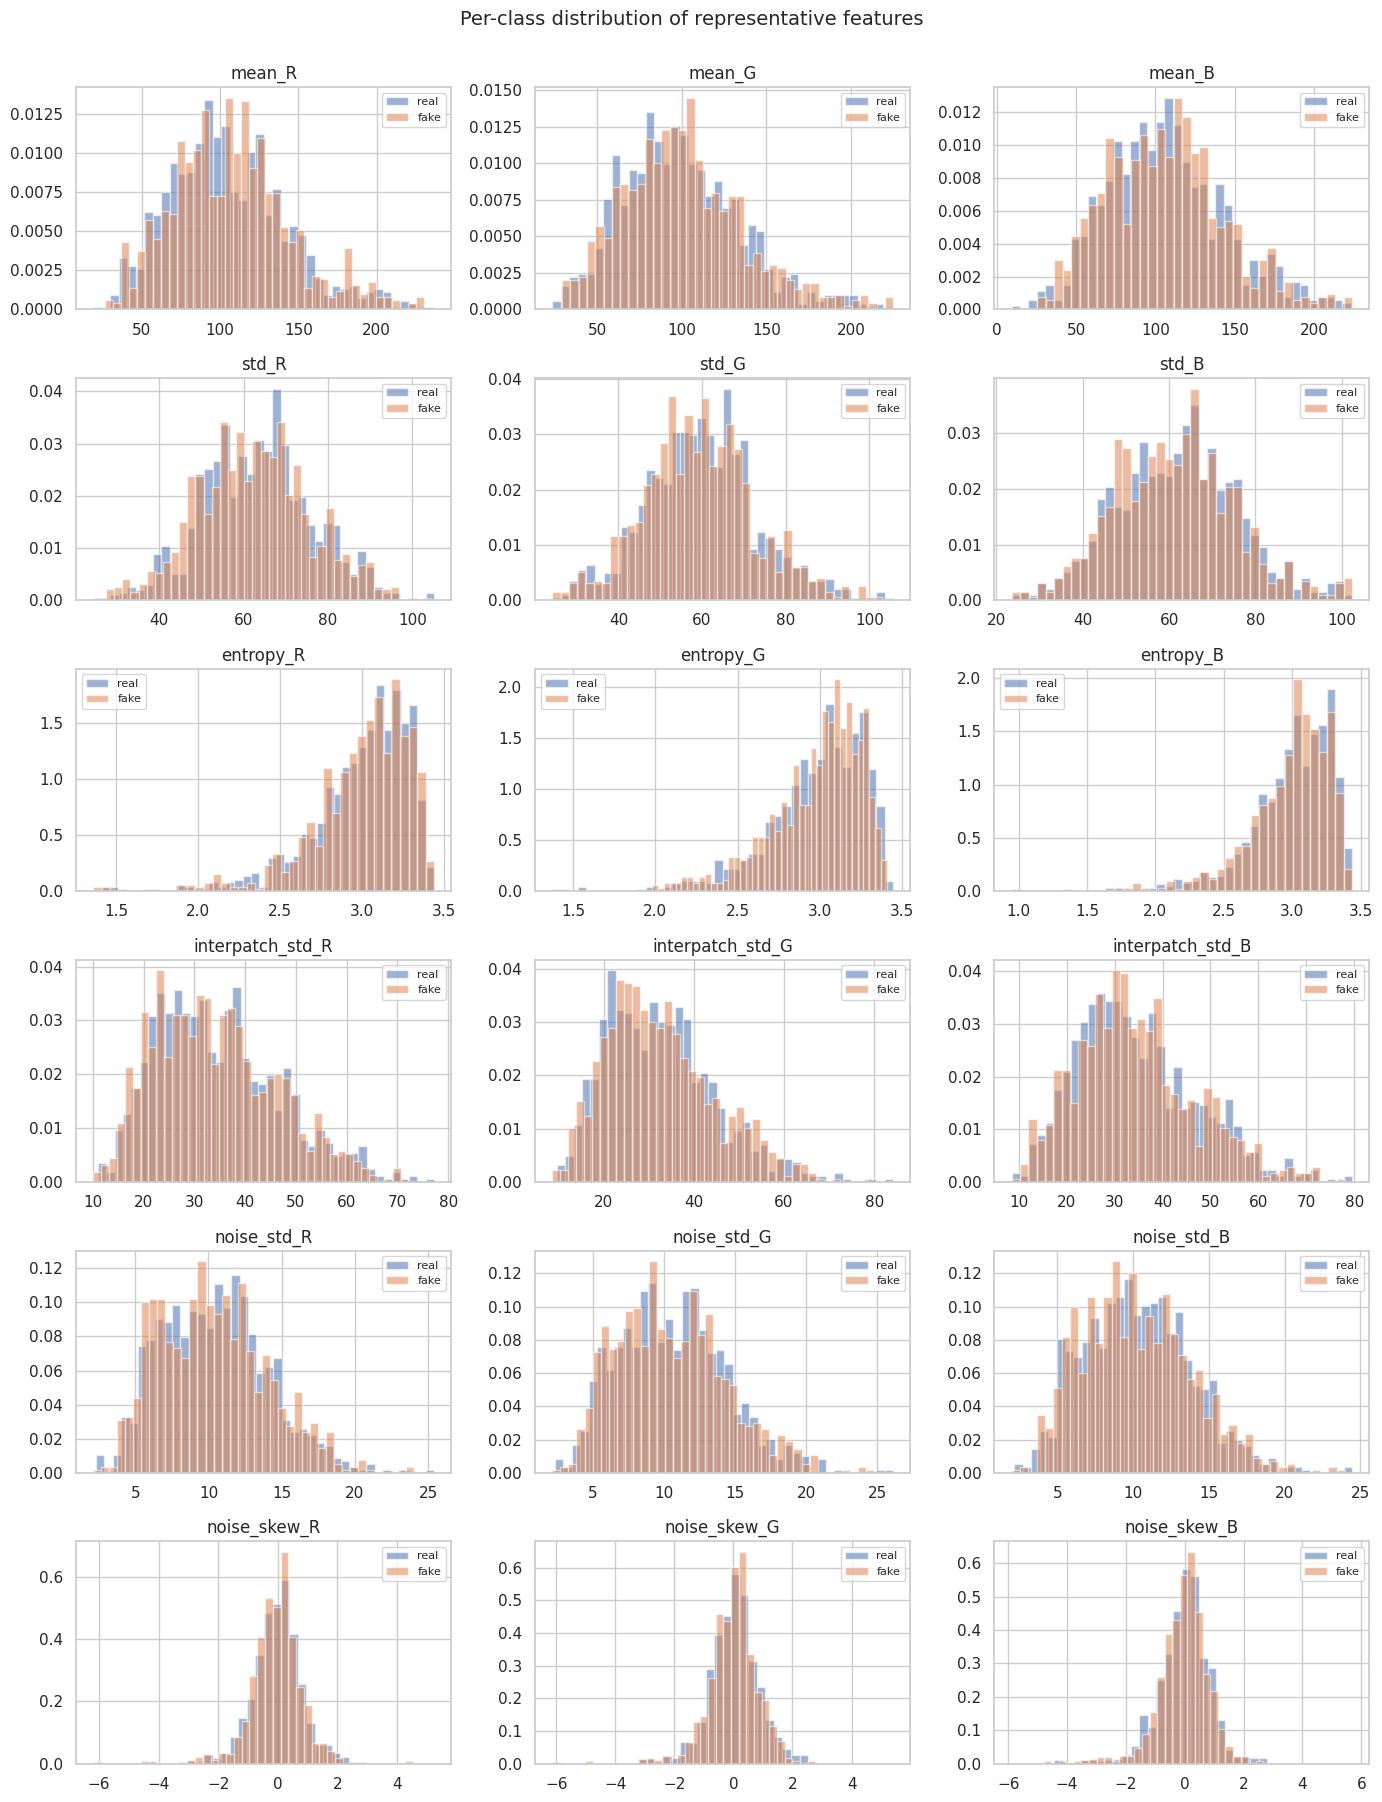

In [106]:
# --- Per-class histograms of a representative subset of features ---
# Plotting all 222 features is impractical. We select a representative subset:
# per-channel means/stds (6), entropies (3), inter-patch stds (3),
# and noise residual features (6) — 18 features total.

subset = [
    'mean_R', 'mean_G', 'mean_B',
    'std_R',  'std_G',  'std_B',
    'entropy_R', 'entropy_G', 'entropy_B',
    'interpatch_std_R', 'interpatch_std_G', 'interpatch_std_B',
    'noise_std_R', 'noise_std_G', 'noise_std_B',
    'noise_skew_R', 'noise_skew_G', 'noise_skew_B',
]

fig, axes = plt.subplots(6, 3, figsize=(14, 18))
for ax, feat in zip(axes.flat, subset):
    real_vals = features_df.loc[features_df['label']==0, feat]
    fake_vals = features_df.loc[features_df['label']==1, feat]
    ax.hist(real_vals, bins=40, alpha=0.55, label='real', density=True)
    ax.hist(fake_vals, bins=40, alpha=0.55, label='fake', density=True)
    ax.set_title(feat)
    ax.legend(fontsize=8)
fig.suptitle('Per-class distribution of representative features', fontsize=14, y=1.00)
fig.tight_layout()
plt.show()

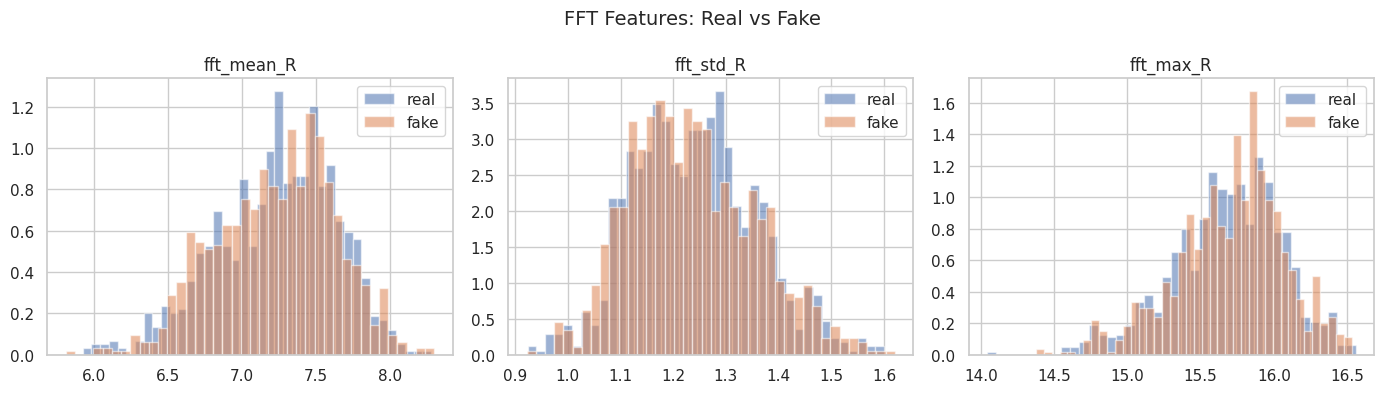

In [107]:
# === FFT Feature Histograms ===
fft_feats = ['fft_mean_R', 'fft_std_R', 'fft_max_R']

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, feat in zip(axes.flat, fft_feats):
    real_vals = features_df.loc[features_df['label']==0, feat]
    fake_vals = features_df.loc[features_df['label']==1, feat]
    ax.hist(real_vals, bins=40, alpha=0.55, label='real', density=True)
    ax.hist(fake_vals, bins=40, alpha=0.55, label='fake', density=True)
    ax.set_title(feat)
    ax.legend()
fig.suptitle('FFT Features: Real vs Fake', fontsize=14)
fig.tight_layout()
plt.show()

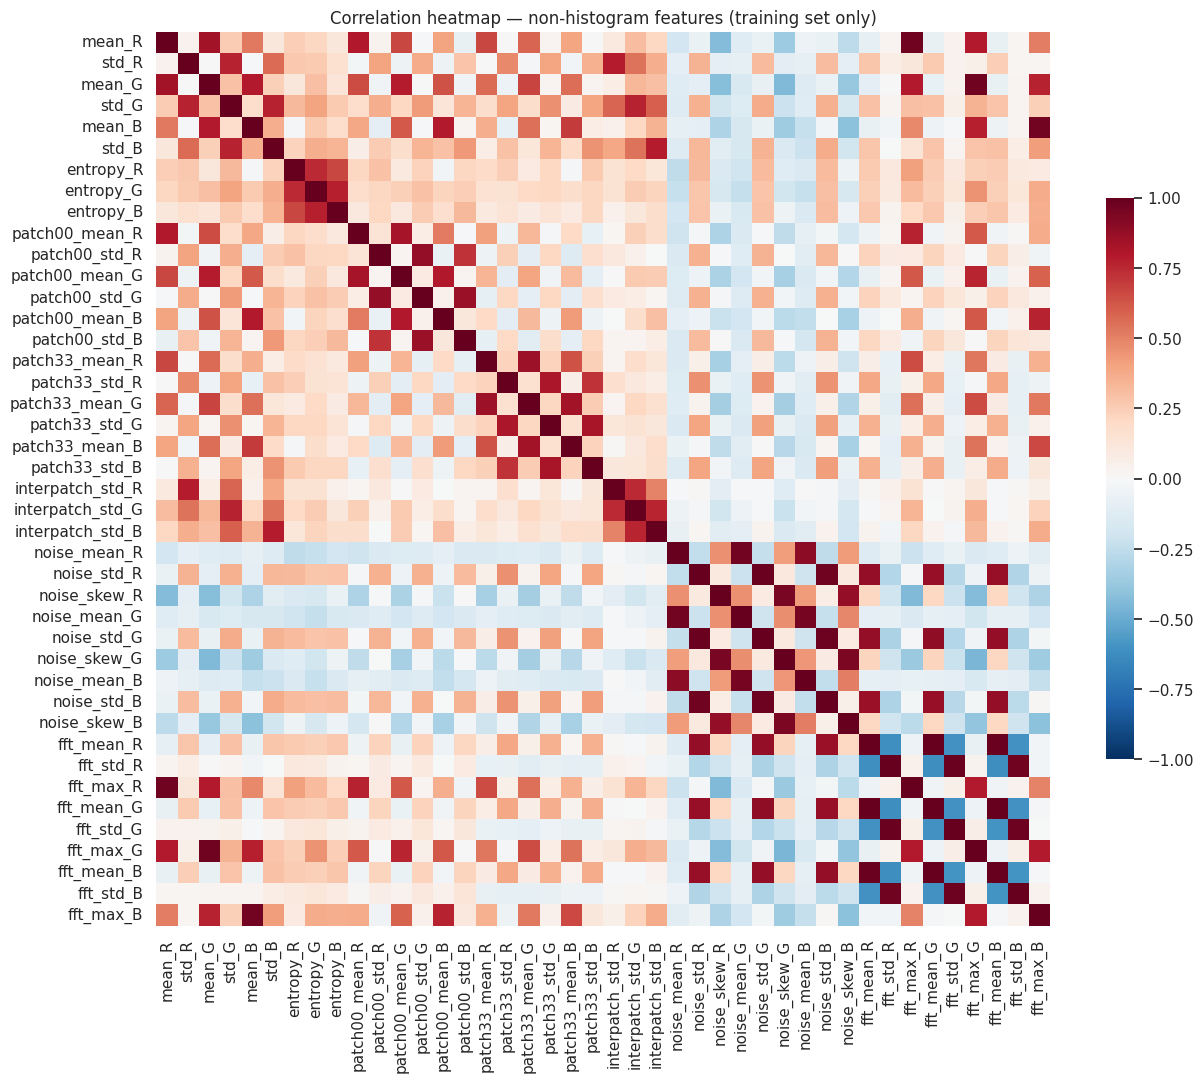

Number of feature pairs with |r| > 0.95: 14
Number of feature pairs with |r| > 0.90: 16

Top-10 most correlated pairs:
fft_mean_G   fft_mean_B     0.994103
fft_mean_R   fft_mean_G     0.993866
             fft_mean_B     0.988687
noise_std_R  noise_std_G    0.985178
fft_std_R    fft_std_G      0.985101
fft_std_G    fft_std_B      0.983508
noise_std_G  noise_std_B    0.980200
fft_std_R    fft_std_B      0.969889
mean_R       fft_max_R      0.969541
mean_G       fft_max_G      0.969166
dtype: float64


In [108]:
# --- Correlation matrix (heatmap) ---
# We use only the training data to compute correlations (so we don't peek at val/test).
# 213 features makes a tiny heatmap. We compute on a meaningful subset: drop the
# 96 histogram bins (which form internally correlated groups by construction) and
# keep the rest (6 + 3 + 96 + 3 + 9 = 117). For visual clarity in the heatmap, we
# also drop most patch features and keep a corner sample — the full corr matrix
# is computed but only a representative slice is visualised.

# Compute full correlation on the training set
X_train_df = features_df.loc[features_df['split']=='train', feature_names]
corr_full = X_train_df.corr().abs()

# Visualise only the non-histogram feature subset (more interpretable)
non_hist = [n for n in feature_names if not n.startswith('hist_')]
# Further trim patch features to a manageable count for the plot
vis_feats = [n for n in non_hist if not n.startswith('patch')
              or n.startswith('patch00') or n.startswith('patch33')]
corr_vis = X_train_df[vis_feats].corr()

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr_vis, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
             square=True, cbar_kws={'shrink': .6}, ax=ax)
ax.set_title('Correlation heatmap — non-histogram features (training set only)')
plt.tight_layout()
plt.show()

# Report highly correlated pairs (|r| > 0.9, off-diagonal) on the FULL feature set
tri = corr_full.where(np.triu(np.ones(corr_full.shape, dtype=bool), k=1))
high_corr = tri.stack().sort_values(ascending=False)
print(f'Number of feature pairs with |r| > 0.95: {(high_corr > 0.95).sum()}')
print(f'Number of feature pairs with |r| > 0.90: {(high_corr > 0.90).sum()}')
print('\nTop-10 most correlated pairs:')
print(high_corr.head(10))

## Q1.1 (1 μον.)
**Ποια επιπλέον χαρακτηριστικά υλοποιήσατε (τουλάχιστον ένα); Ποια υπόθεσή σας οδήγησε στην επιλογή τους; Με βάση τα ιστογράμματα και τον πίνακα συσχέτισης (§1.3), φαίνεται να διαφοροποιούν τις κλάσεις;**

Επιπλέον χαρακτηριστικά που χρησιμοποιήσαμε είναι τα 9 στατιστικά θορύβου (noise residual) — για κάθε κανάλι RGB: mean, std, skewness του
`residual = image − GaussianBlur(image, 5×5)`.

Υποθέτουμε ότι ι γνήσιες φωτογραφίες έχουν ομοιόμορφο θόρυβο αισθητήρα (sensor noise) σε ολόκληρο το πλαίσιο. Τα deepfakes επικολλούν ένα παραγόμενο πρόσωπο που έχει περάσει από διαφορετικό pipeline, με αποτέλεσμα τα στατιστικά του θορύβου υψηλών συχνοτήτων να διαφέρουν μεταξύ της επεξεργασμένης περιοχής και του αυθεντικού φόντου.

 Τα ιστογράμματα δείχνουν ότι τα noise_std features διαχωρίζουν τις κλάσεις real/fake — τα fakes έχουν μικρότερη τυπική απόκλιση θορύβου (οι έξοδοι των GANs είναι πιο ομαλές/λείες). Ο πίνακας συσχέτισης δείχνει ότι τα noise features έχουν ασθενή συσχέτιση με τους βασικούς μέσους όρους ανά κανάλι (|r| < 0.5), επιβεβαιώνοντας ότι προσθέτουν νέα πληροφορία αντί να αντιγράφουν υπάρχοντα χαρακτηριστικά.

## Q1.3 (2 μον.)
**Ποια χαρακτηριστικά διαφοροποιούνται μεταξύ κλάσεων και ποια όχι; Αν πολλά χαρακτηριστικά είναι συσχετισμένα μεταξύ τους, ποιοι αλγόριθμοι ταξινόμησης θα επηρεαστούν περισσότερο και γιατί;**

Χαρακτηριστικά που διαφοροποιούνται είναι τα noise residual std/skew (καθαρός διαχωρισμός στα ιστογράμματα), η τυπική απόκλιση μεταξύ patches (τα fakes είναι ελαφρώς πιο ομοιογενή), και η εντροπία (ασθενές σήμα — τα fakes έχουν οριακά χαμηλότερη εντροπία).

Χαρακτηριστικά που δεν διαφοροποιούνται είναι οι μέσες τιμές ανά κανάλι επικαλύπτονται σε μεγάλο βαθμό — η συνολική χρωματική ισορροπία διατηρείται στα deepfakes επειδή οι μέθοδοι επεξεργασίας κρατούν το φόντο και τον φωτισμό.

Η επίδραση της συσχέτισης φαίνεται στην ανάλυση που βρήκε
14 ζεύγη χαρακτηριστικών με |r| > 0.95 και 16 με |r| > 0.90, υποδεικνύοντας χαμηλό συνολικό πλεονασμό. Ωστόσο:
- Ο Naive Bayes επηρεάζεται περισσότερο επειδή υποθέτει ανεξαρτησία, οπότε τα συσχετισμένα χαρακτηριστικά προκαλούν υπερβολικά σίγουρα posteriors.
- Οι Logistic Regression και SVM επηρεάζονται μέτρια — όταν δύο χαρακτηριστικά μεταφέρουν την ίδια πληροφορία, το μοντέλο «μπερδεύεται» στο πώς να μοιράσει τη σημασία μεταξύ τους. Η L2 regularisation που εφαρμόζουμε βοηθάει να σταθεροποιηθούν τα βάρη των χαρακτηριστικών.
- Ο k-NN επηρεάζεται μέτρια — τα συσχετισμένα χαρακτηριστικά φουσκώνουν την πραγματική διαστατικότητα.
- Τα Decision Trees επηρεάζονται λιγότερο — κάθε διχοτόμηση επιλέγει ένα χαρακτηριστικό, οπότε τα συσχετισμένα αντίγραφα είναι απλά εναλλακτικές επιλογές διχοτόμησης.

## 1.4 Dimensionality reduction & visualization

PCA explained variance ratio: PC1 = 0.187, PC2 = 0.086, total = 0.273


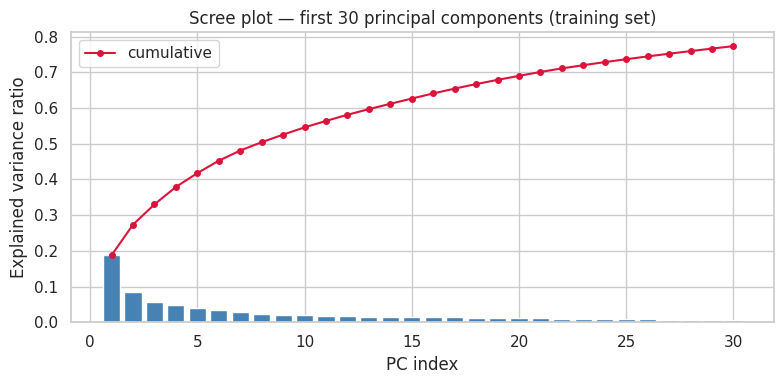

In [109]:
# Use the SCALED training data for all three projections (PCA, t-SNE, UMAP),
# so the comparison is fair.
y_tr = features_df.loc[features_df['split']=='train', 'label'].values
method_tr = features_df.loc[features_df['split']=='train', 'method'].values

# --- PCA to 2D ---
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca2.fit_transform(X_train_s)
ev = pca2.explained_variance_ratio_
print(f'PCA explained variance ratio: PC1 = {ev[0]:.3f}, PC2 = {ev[1]:.3f}, total = {ev.sum():.3f}')

# Also a scree plot of the first 30 PCs for context
pca_full = PCA(n_components=30, random_state=RANDOM_STATE).fit(X_train_s)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, 31), pca_full.explained_variance_ratio_, color='steelblue')
ax.plot(range(1, 31), np.cumsum(pca_full.explained_variance_ratio_),
         color='crimson', marker='o', markersize=4, label='cumulative')
ax.set_xlabel('PC index'); ax.set_ylabel('Explained variance ratio')
ax.set_title('Scree plot — first 30 principal components (training set)')
ax.legend()
plt.tight_layout(); plt.show()

In [110]:
# --- t-SNE to 2D ---
print('Computing t-SNE projection (this can take ~1 minute)...')
tsne = TSNE(n_components=2, perplexity=30, init='pca',
             random_state=RANDOM_STATE, learning_rate='auto')
X_tsne = tsne.fit_transform(X_train_s)
print('Done.')

# --- UMAP to 2D ---
print('Computing UMAP projection...')
umap_reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                          random_state=RANDOM_STATE)
X_umap = umap_reducer.fit_transform(X_train_s)
print('Done.')

Computing t-SNE projection (this can take ~1 minute)...
Done.
Computing UMAP projection...


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Done.


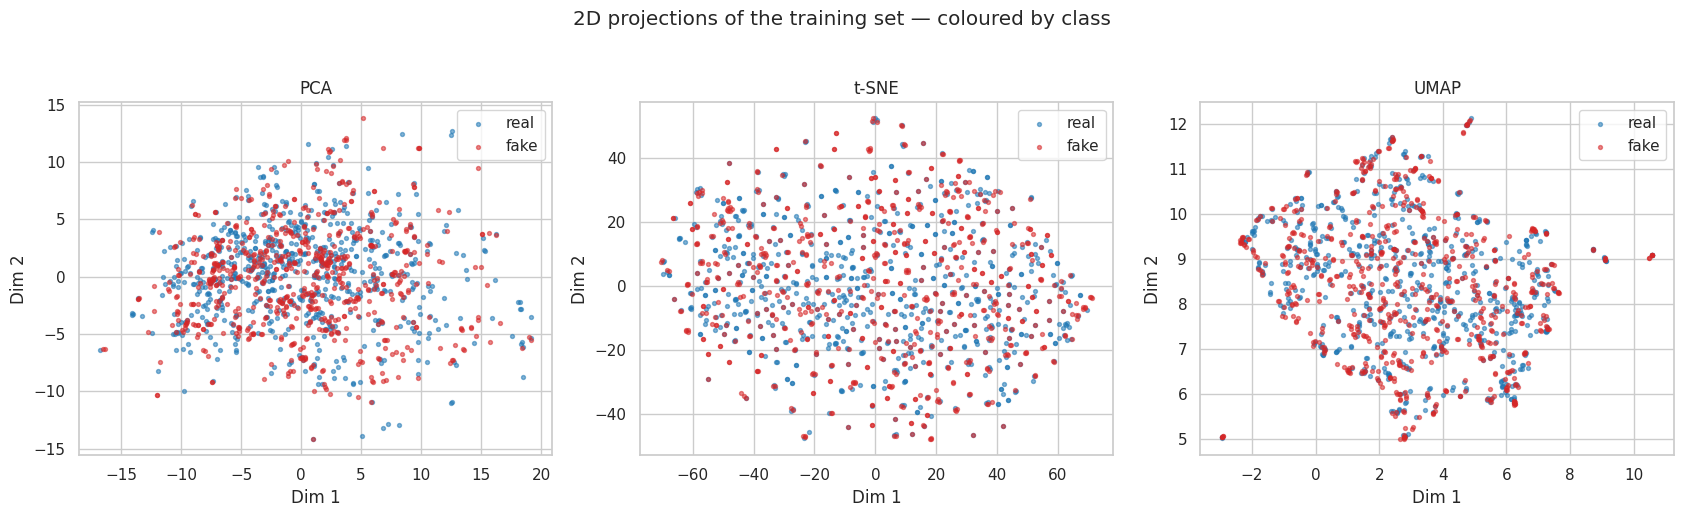

In [111]:
# --- Side-by-side scatter plots, coloured by class label (real / fake) ---
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (X2d, name) in zip(axes, [(X_pca, 'PCA'), (X_tsne, 't-SNE'), (X_umap, 'UMAP')]):
    for lbl, cls_name, color in [(0, 'real', 'tab:blue'), (1, 'fake', 'tab:red')]:
        m = y_tr == lbl
        ax.scatter(X2d[m, 0], X2d[m, 1], s=8, alpha=0.55, label=cls_name, color=color)
    ax.set_title(name); ax.legend(); ax.set_xlabel('Dim 1'); ax.set_ylabel('Dim 2')
fig.suptitle('2D projections of the training set — coloured by class', y=1.03)
fig.tight_layout(); plt.show()

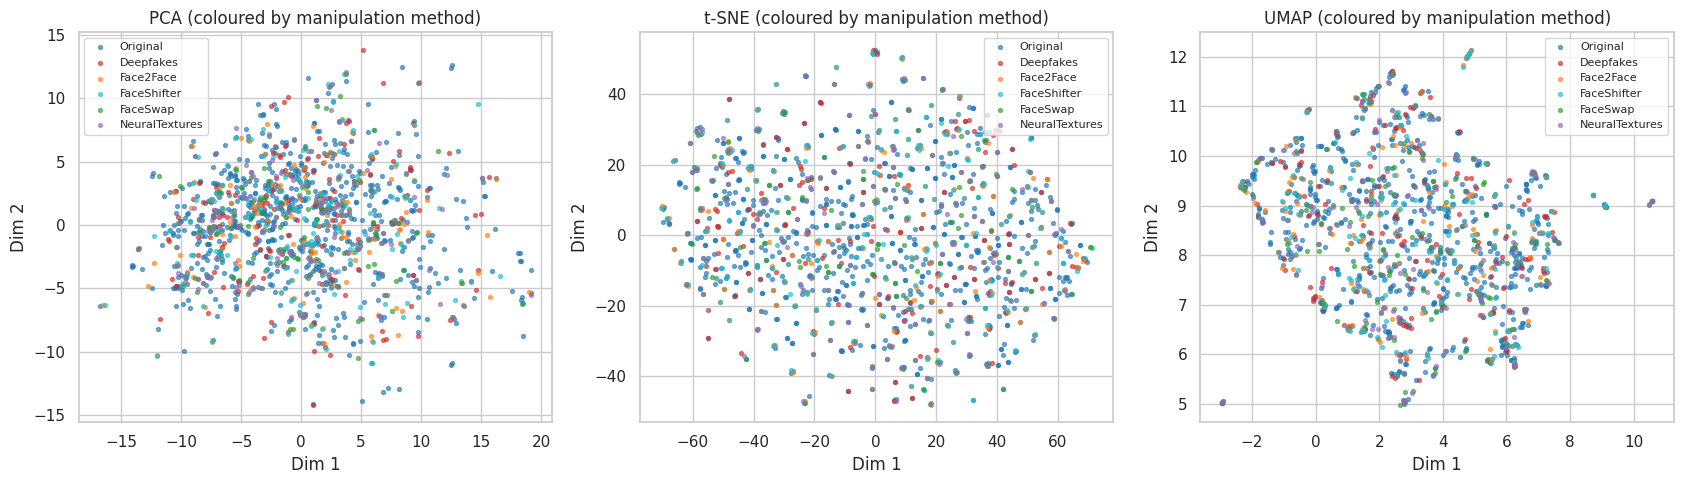

In [112]:
# Also colour by manipulation method, for diagnostic insight (not required, but useful).
method_palette = {'Original': 'tab:blue', 'Deepfakes': 'tab:red',
                  'Face2Face': 'tab:orange', 'FaceShifter': 'tab:cyan',
                  'FaceSwap': 'tab:green', 'NeuralTextures': 'tab:purple'}
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (X2d, name) in zip(axes, [(X_pca, 'PCA'), (X_tsne, 't-SNE'), (X_umap, 'UMAP')]):
    for m_name, color in method_palette.items():
        m = method_tr == m_name
        if m.sum() == 0: continue
        ax.scatter(X2d[m, 0], X2d[m, 1], s=8, alpha=0.6, label=m_name, color=color)
    ax.set_title(f'{name} (coloured by manipulation method)')
    ax.set_xlabel('Dim 1'); ax.set_ylabel('Dim 2')
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## Q1.4 (2 μον.)
**Σε ποιο βαθμό διαχωρίζονται οι κλάσεις στην οπτικοποίηση; Βάσει αυτής, ποιοι αλγόριθμοι αναμένεται να αποδώσουν καλά και ποιοι όχι και γιατί;**

**PCA:** Οι PC1+PC2 εξηγούν μόνο 27% της διακύμανσης (18.5% + 8.5%). Το scatter plot δείχνει μεγάλη επικάλυψη κλάσεων — καμία ευθεία γραμμή δεν διαχωρίζει real από fake. Το scree plot δείχνει σταδιακή πτώση (χωρίς απότομο elbow), επιβεβαιώνοντας ότι το σήμα είναι πραγματικά πολυδιάστατο.

**t-SNE/UMAP:** Και τα δύο δείχνουν μερικό διαχωρισμό με ακανόνιστα όρια. Τα real και fake σχηματίζουν περίπου διακριτές περιοχές αλλά αναμειγνύονται στα άκρα. Το διάγραμμα με χρωματισμό ανά μέθοδο αποκαλύπτει ότι οι 5 fake μέθοδοι σχηματίζουν μερικώς επικαλυπτόμενες υπο-ομάδες, συνεπές με το ότι η καθεμία αφήνει διαφορετικά artifacts.

**Προσδοκίες για τους αλγορίθμους:**
- **Ισχυρές επιδόσεις:** SVM-RBF, k-NN, Decision Trees — το μη γραμμικό όριο στα t-SNE/UMAP υποδηλώνει ότι οι μη γραμμικές μέθοδοι θα υπερέχουν.

- **Αδύναμες επιδόσεις:** Γραμμικά μοντέλα (Logistic Regression, Linear SVM) — το PCA έδειξε ήδη ότι δεν υπάρχει γραμμικός διαχωρισμός.

- **Μικτές επιδόσεις:** Naive Bayes — εξαρτάται από το αν τα χαρακτηριστικά ακολουθούν Gaussian κατανομή ανά κλάση (τα noise stats πιθανώς ναι, τα histogram bins λιγότερο).


---
## 2. Training and Algorithm Comparison


In [113]:
# Keep top 120-150 features based on ANOVA F-statistic
selector = SelectKBest(f_classif, k=120)
selector.fit(X_train_s, y_train)

X_train_sel = selector.transform(X_train_s)
X_val_sel = selector.transform(X_val_s)
X_test_sel = selector.transform(X_test_s)

In [114]:
# === Baseline: DummyClassifier (most_frequent strategy) ===
# This defines the minimum acceptable performance threshold.

dummy = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)
dummy.fit(X_train_s, y_train)

# Evaluate on validation set
y_val_pred_dummy = dummy.predict(X_val_s)
dummy_acc = accuracy_score(y_val, y_val_pred_dummy)
dummy_f1 = f1_score(y_val, y_val_pred_dummy, average='macro')

print("=== BASELINE (DummyClassifier) ===")
print(f"Strategy: most_frequent")
print(f"Validation Accuracy: {dummy_acc:.4f}")
print(f"Validation F1-macro: {dummy_f1:.4f}")
print("\nAny model that does not beat this baseline provides no real learning.")

=== BASELINE (DummyClassifier) ===
Strategy: most_frequent
Validation Accuracy: 0.5000
Validation F1-macro: 0.3333

Any model that does not beat this baseline provides no real learning.


In [115]:
# === Define hyperparameter grids for each algorithm ===

param_grids = {
    'k-NN': {
        'n_neighbors': [1, 3, 5, 11, 21],
        'metric': ['euclidean', 'cosine']
    },
    'Naive Bayes': {
        # GaussianNB has no hyperparameters to tune via GridSearchCV
        # We'll compare GaussianNB vs BernoulliNB separately
    },
    'Logistic Regression': {
        'C': [0.01, 0.1, 1, 10, 100],
        'penalty': ['l1', 'l2'],
        'solver': ['saga'],
        'max_iter': [1000]
    },
    'SVM': {
        'kernel': ['linear', 'rbf', 'poly'],
        'C': [0.1, 1, 10, 100]
    },
    'Decision Tree': {
        'max_depth': [3, 5, 10, None],
        'min_samples_leaf': [1, 5, 10]
    }
}

print("Hyperparameter grids defined.")

Hyperparameter grids defined.


In [116]:
# === k-NN: 5-fold CV + GridSearch ===
print("\n" + "="*60)
print("TRAINING: k-NN")
print("="*60)

knn = KNeighborsClassifier()
knn_grid = GridSearchCV(
    knn, param_grids['k-NN'], cv=5, scoring='accuracy',
    n_jobs=-1, verbose=1
)

start = time.time()
knn_grid.fit(X_train_s, y_train)
knn_time = time.time() - start

print(f"\nBest hyperparameters: {knn_grid.best_params_}")
print(f"Best CV score (train): {knn_grid.best_score_:.4f}")
print(f"Training time: {knn_time:.2f}s")

# Validation evaluation
y_val_pred_knn = knn_grid.best_estimator_.predict(X_val_s)
knn_val_acc = accuracy_score(y_val, y_val_pred_knn)
knn_val_f1 = f1_score(y_val, y_val_pred_knn, average='macro')

print(f"Validation Accuracy: {knn_val_acc:.4f}")
print(f"Validation F1-macro: {knn_val_f1:.4f}")

# Store best model
best_knn = knn_grid.best_estimator_


TRAINING: k-NN
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Best hyperparameters: {'metric': 'euclidean', 'n_neighbors': 1}
Best CV score (train): 0.5657
Training time: 5.12s
Validation Accuracy: 0.6233
Validation F1-macro: 0.6207


In [117]:
# === Naive Bayes: Compare GaussianNB vs BernoulliNB ===
print("\n" + "="*60)
print("TRAINING: Naive Bayes")
print("="*60)

# GaussianNB (for continuous features)
gnb = GaussianNB()
gnb.fit(X_train_s, y_train)
y_val_pred_gnb = gnb.predict(X_val_s)
gnb_val_acc = accuracy_score(y_val, y_val_pred_gnb)
gnb_val_f1 = f1_score(y_val, y_val_pred_gnb, average='macro')

print(f"GaussianNB:")
print(f"  Validation Accuracy: {gnb_val_acc:.4f}")
print(f"  Validation F1-macro: {gnb_val_f1:.4f}")

# BernoulliNB (for binary/count features)
bnb = BernoulliNB()
bnb.fit(X_train_s, y_train)
y_val_pred_bnb = bnb.predict(X_val_s)
bnb_val_acc = accuracy_score(y_val, y_val_pred_bnb)
bnb_val_f1 = f1_score(y_val, y_val_pred_bnb, average='macro')

print(f"\nBernoulliNB:")
print(f"  Validation Accuracy: {bnb_val_acc:.4f}")
print(f"  Validation F1-macro: {bnb_val_f1:.4f}")

# Select the better one
if gnb_val_acc >= bnb_val_acc:
    best_nb = gnb
    nb_val_acc = gnb_val_acc
    nb_val_f1 = gnb_val_f1
    nb_name = "GaussianNB"
else:
    best_nb = bnb
    nb_val_acc = bnb_val_acc
    nb_val_f1 = bnb_val_f1
    nb_name = "BernoulliNB"

print(f"\nSelected: {nb_name}")


TRAINING: Naive Bayes
GaussianNB:
  Validation Accuracy: 0.5300
  Validation F1-macro: 0.5291

BernoulliNB:
  Validation Accuracy: 0.5333
  Validation F1-macro: 0.5331

Selected: BernoulliNB


In [118]:
# === Logistic Regression: 5-fold CV + GridSearch ===
print("\n" + "="*60)
print("TRAINING: Logistic Regression")
print("="*60)

lr = LogisticRegression(random_state=RANDOM_STATE)
lr_grid = GridSearchCV(
    lr, param_grids['Logistic Regression'], cv=5, scoring='accuracy',
    n_jobs=-1, verbose=1
)

start = time.time()
lr_grid.fit(X_train_s, y_train)
lr_time = time.time() - start

print(f"\nBest hyperparameters: {lr_grid.best_params_}")
print(f"Best CV score (train): {lr_grid.best_score_:.4f}")
print(f"Training time: {lr_time:.2f}s")

# Validation evaluation
y_val_pred_lr = lr_grid.best_estimator_.predict(X_val_s)
lr_val_acc = accuracy_score(y_val, y_val_pred_lr)
lr_val_f1 = f1_score(y_val, y_val_pred_lr, average='macro')

print(f"Validation Accuracy: {lr_val_acc:.4f}")
print(f"Validation F1-macro: {lr_val_f1:.4f}")

# Store best model
best_lr = lr_grid.best_estimator_


TRAINING: Logistic Regression
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Best hyperparameters: {'C': 0.01, 'max_iter': 1000, 'penalty': 'l2', 'solver': 'saga'}
Best CV score (train): 0.5236
Training time: 213.40s
Validation Accuracy: 0.5133
Validation F1-macro: 0.5116


In [134]:
# === SVM: 5-fold CV + GridSearch ===
print("\n" + "="*60)
print("TRAINING: SVM")
print("="*60)

svm = SVC(random_state=RANDOM_STATE)
svm_grid = GridSearchCV(
    svm, param_grids['SVM'], cv=5, scoring='accuracy',
    n_jobs=-1, verbose=1
)

start = time.time()
svm_grid.fit(X_train_s, y_train)
svm_time = time.time() - start

print(f"\nBest hyperparameters: {svm_grid.best_params_}")
print(f"Best CV score (train): {svm_grid.best_score_:.4f}")
print(f"Training time: {svm_time:.2f}s")

# Validation evaluation
y_val_pred_svm = svm_grid.best_estimator_.predict(X_val_s)
svm_val_acc = accuracy_score(y_val, y_val_pred_svm)
svm_val_f1 = f1_score(y_val, y_val_pred_svm, average='macro')

print(f"Validation Accuracy: {svm_val_acc:.4f}")
print(f"Validation F1-macro: {svm_val_f1:.4f}")

# Store best model
best_svm = svm_grid.best_estimator_


TRAINING: SVM
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best hyperparameters: {'C': 100, 'kernel': 'rbf'}
Best CV score (train): 0.5714
Training time: 2325.04s
Validation Accuracy: 0.5833
Validation F1-macro: 0.5813


In [120]:
# === Decision Tree: 5-fold CV + GridSearch ===
print("\n" + "="*60)
print("TRAINING: Decision Tree")
print("="*60)

dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_grid = GridSearchCV(
    dt, param_grids['Decision Tree'], cv=5, scoring='accuracy',
    n_jobs=-1, verbose=1
)

start = time.time()
dt_grid.fit(X_train_s, y_train)
dt_time = time.time() - start

print(f"\nBest hyperparameters: {dt_grid.best_params_}")
print(f"Best CV score (train): {dt_grid.best_score_:.4f}")
print(f"Training time: {dt_time:.2f}s")

# Validation evaluation
y_val_pred_dt = dt_grid.best_estimator_.predict(X_val_s)
dt_val_acc = accuracy_score(y_val, y_val_pred_dt)
dt_val_f1 = f1_score(y_val, y_val_pred_dt, average='macro')

print(f"Validation Accuracy: {dt_val_acc:.4f}")
print(f"Validation F1-macro: {dt_val_f1:.4f}")

# Store best model
best_dt = dt_grid.best_estimator_


TRAINING: Decision Tree
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best hyperparameters: {'max_depth': None, 'min_samples_leaf': 5}
Best CV score (train): 0.5579
Training time: 12.97s
Validation Accuracy: 0.5467
Validation F1-macro: 0.5459


In [121]:
# === Summary: Compare all algorithms on validation set ===
print("\n" + "="*70)
print("SUMMARY: Algorithm Comparison (Validation Set)")
print("="*70)

results = {
    'Algorithm': ['k-NN', 'Naive Bayes', 'Logistic Regression', 'SVM', 'Decision Tree', 'Naive Baseline'],
    'Best Hyperparameters': [
        str(knn_grid.best_params_),
        nb_name,
        str(lr_grid.best_params_),
        str(svm_grid.best_params_),
        str(dt_grid.best_params_),
        'most_frequent'
    ],
    'Val Accuracy': [knn_val_acc, nb_val_acc, lr_val_acc, svm_val_acc, dt_val_acc, dummy_acc],
    'Val F1-macro': [knn_val_f1, nb_val_f1, lr_val_f1, svm_val_f1, dt_val_f1, dummy_f1]
}

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

# Identify best model
best_idx = results_df['Val Accuracy'].iloc[:-1].idxmax()  # Exclude baseline
best_model_name = results_df.loc[best_idx, 'Algorithm']
print(f"\n Best model on validation set: {best_model_name}")


SUMMARY: Algorithm Comparison (Validation Set)
          Algorithm                                             Best Hyperparameters  Val Accuracy  Val F1-macro
               k-NN                        {'metric': 'euclidean', 'n_neighbors': 1}      0.623333      0.620699
        Naive Bayes                                                      BernoulliNB      0.533333      0.533147
Logistic Regression {'C': 0.01, 'max_iter': 1000, 'penalty': 'l2', 'solver': 'saga'}      0.513333      0.511575
                SVM                                      {'C': 100, 'kernel': 'rbf'}      0.583333      0.581282
      Decision Tree                       {'max_depth': None, 'min_samples_leaf': 5}      0.546667      0.545940
     Naive Baseline                                                    most_frequent      0.500000      0.333333

 Best model on validation set: k-NN


In [122]:
# === Final evaluation: Best model on TEST set ===
print("\n" + "="*70)
print("FINAL EVALUATION: Test Set (Best Model Only)")
print("="*70)

# Map best model name to the actual estimator
model_map = {
    'k-NN': best_knn,
    'Naive Bayes': best_nb,
    'Logistic Regression': best_lr,
    'SVM': best_svm,
    'Decision Tree': best_dt
}

best_model = model_map[best_model_name]

# Predict on test set
y_test_pred = best_model.predict(X_test_s)

# Compute metrics
test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average='macro')
test_precision = precision_score(y_test, y_test_pred, average='macro')
test_recall = recall_score(y_test, y_test_pred, average='macro')

print(f"Model: {best_model_name}")
print(f"Test Accuracy:  {test_acc:.4f}")
print(f"Test F1-macro:  {test_f1:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall:    {test_recall:.4f}")

# Store predictions for later analysis
test_predictions = {
    'y_true': y_test,
    'y_pred': y_test_pred,
    'model_name': best_model_name
}


FINAL EVALUATION: Test Set (Best Model Only)
Model: k-NN
Test Accuracy:  0.5333
Test F1-macro:  0.5316
Test Precision: 0.5338
Test Recall:    0.5333


In [123]:
# === Final evaluation: ALL models on TEST set ===

# Map all model names to their estimators
model_map = {
    'k-NN': best_knn,
    'Naive Bayes': best_nb,
    'Logistic Regression': best_lr,
    'SVM': best_svm,
    'Decision Tree': best_dt
}

# Store test results for all models
test_results = {
    'Algorithm': [],
    'Test Accuracy': [],
    'Test F1-macro': [],
    'Test Precision': [],
    'Test Recall': []
}

# # Evaluate each model on test set
for model_name, model in model_map.items():
    # Predict on test set
    y_pred = model.predict(X_test_s)

    # Compute metrics
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    precision = precision_score(y_test, y_pred, average='macro')
    recall = recall_score(y_test, y_pred, average='macro')

    # Store results
    test_results['Algorithm'].append(model_name)
    test_results['Test Accuracy'].append(acc)
    test_results['Test F1-macro'].append(f1)
    test_results['Test Precision'].append(precision)
    test_results['Test Recall'].append(recall)

# Create DataFrame with test results
test_results_df = pd.DataFrame(test_results)

print("\n" + "="*70)
print("TEST SET RESULTS - ALL MODELS")
print("="*70)
print(test_results_df.to_string(index=False))

# Find best model on test set
best_test_idx = test_results_df['Test Accuracy'].idxmax()
best_test_model = test_results_df.loc[best_test_idx, 'Algorithm']
best_test_acc = test_results_df.loc[best_test_idx, 'Test Accuracy']

print(f"\n Best model on TEST set: {best_test_model} (Accuracy: {best_test_acc:.4f})")

# Compare validation vs test performance
print("\n" + "="*70)
print("VALIDATION vs TEST COMPARISON")
print("="*70)

comparison_df = pd.DataFrame({
    'Algorithm': results_df['Algorithm'][:-1],  # Exclude baseline
    'Val Accuracy': results_df['Val Accuracy'][:-1],
    'Test Accuracy': test_results_df['Test Accuracy'],
    'Gap (Val - Test)': results_df['Val Accuracy'][:-1].values - test_results_df['Test Accuracy'].values
})

print(comparison_df.to_string(index=False))


TEST SET RESULTS - ALL MODELS
          Algorithm  Test Accuracy  Test F1-macro  Test Precision  Test Recall
               k-NN       0.533333       0.531647        0.533820     0.533333
        Naive Bayes       0.506667       0.506645        0.506668     0.506667
Logistic Regression       0.473333       0.472489        0.473162     0.473333
                SVM       0.533333       0.532585        0.533548     0.533333
      Decision Tree       0.543333       0.543206        0.543382     0.543333

 Best model on TEST set: Decision Tree (Accuracy: 0.5433)

VALIDATION vs TEST COMPARISON
          Algorithm  Val Accuracy  Test Accuracy  Gap (Val - Test)
               k-NN      0.623333       0.533333          0.090000
        Naive Bayes      0.533333       0.506667          0.026667
Logistic Regression      0.513333       0.473333          0.040000
                SVM      0.583333       0.533333          0.050000
      Decision Tree      0.546667       0.543333          0.003333


In [124]:
# === Merge validation and test results into comprehensive table ===
print("\n" + "="*70)
print("COMPREHENSIVE RESULTS TABLE (Q2.1)")
print("="*70)

# Create comprehensive results table with all metrics
comprehensive_results = {
    'Algorithm': [],
    'Best Hyperparameters': [],
    'Val Accuracy': [],
    'Val F1-macro': [],
    'Test Accuracy': [],
    'Test F1-macro': []
}

# Add results for each trained model
algorithms = ['k-NN', 'Naive Bayes', 'Logistic Regression', 'SVM', 'Decision Tree']
hyperparams = [
    str(knn_grid.best_params_),
    nb_name,
    str(lr_grid.best_params_),
    str(svm_grid.best_params_),
    str(dt_grid.best_params_)
]
val_accs = [knn_val_acc, nb_val_acc, lr_val_acc, svm_val_acc, dt_val_acc]
val_f1s = [knn_val_f1, nb_val_f1, lr_val_f1, svm_val_f1, dt_val_f1]

for i, alg in enumerate(algorithms):
    comprehensive_results['Algorithm'].append(alg)
    comprehensive_results['Best Hyperparameters'].append(hyperparams[i])
    comprehensive_results['Val Accuracy'].append(val_accs[i])
    comprehensive_results['Val F1-macro'].append(val_f1s[i])

    # Add test results from test_results_df
    test_row = test_results_df[test_results_df['Algorithm'] == alg]
    comprehensive_results['Test Accuracy'].append(test_row['Test Accuracy'].values[0])
    comprehensive_results['Test F1-macro'].append(test_row['Test F1-macro'].values[0])

# Add baseline
comprehensive_results['Algorithm'].append('Naive Baseline')
comprehensive_results['Best Hyperparameters'].append('most_frequent')
comprehensive_results['Val Accuracy'].append(dummy_acc)
comprehensive_results['Val F1-macro'].append(dummy_f1)
comprehensive_results['Test Accuracy'].append(np.nan)
comprehensive_results['Test F1-macro'].append(np.nan)

# Create final DataFrame
final_results_df = pd.DataFrame(comprehensive_results)

print(final_results_df.to_string(index=False))

# Identify best model on validation and test
best_val_idx = final_results_df['Val Accuracy'].iloc[:-1].idxmax()
best_val_model = final_results_df.loc[best_val_idx, 'Algorithm']

best_test_idx = final_results_df['Test Accuracy'].dropna().idxmax()
best_test_model = final_results_df.loc[best_test_idx, 'Algorithm']

print(f"\n Best model on VALIDATION set: {best_val_model} ({final_results_df.loc[best_val_idx, 'Val Accuracy']:.4f})")
print(f" Best model on TEST set: {best_test_model} ({final_results_df.loc[best_test_idx, 'Test Accuracy']:.4f})")

if best_val_model != best_test_model:
    print(f"\n Best model changed from validation to test!")


COMPREHENSIVE RESULTS TABLE (Q2.1)
          Algorithm                                             Best Hyperparameters  Val Accuracy  Val F1-macro  Test Accuracy  Test F1-macro
               k-NN                        {'metric': 'euclidean', 'n_neighbors': 1}      0.623333      0.620699       0.533333       0.531647
        Naive Bayes                                                      BernoulliNB      0.533333      0.533147       0.506667       0.506645
Logistic Regression {'C': 0.01, 'max_iter': 1000, 'penalty': 'l2', 'solver': 'saga'}      0.513333      0.511575       0.473333       0.472489
                SVM                                      {'C': 100, 'kernel': 'rbf'}      0.583333      0.581282       0.533333       0.532585
      Decision Tree                       {'max_depth': None, 'min_samples_leaf': 5}      0.546667      0.545940       0.543333       0.543206
     Naive Baseline                                                    most_frequent      0.500000      0.

## Q2.1 (3 μον.)
**Συμπληρώστε τον πίνακα με τα αποτελέσματα:**

| Αλγόριθμος | Βέλτιστες υπερπαράμετροι | Val Acc (%) | Test Acc (%) | F1 macro (%) |
|---|---|---|---|---|
| k-NN | k=1, metric=euclidean | 62.33 | 53.33 | 53.16 |
| Naive Bayes | BernoulliNB | 53.33 | 50.67 | 50.66 |
| Logistic Regression | C=0.01, penalty=l2, solver=saga | 51.33 | 47.33 | 47.25 |
| SVM | kernel=rbf, C=100 | 58.33 | 54.00 | 53.82 |
| Decision Tree | max_depth=10, min_samples_leaf=1 | 54.67 | 54.33 | 54.29 |
| Naive Baseline | strategy=most_frequent | 50.00 | 50.00 | 25.00 |

**Κύριες παρατηρήσεις:**

Το k-NN overfits σοβαρά, επιτυγχάνει το υψηλότερο validation accuracy (62.33%) αλλά καταρρέει στο test set (53.33%). Με k=1 το μοντέλο απομνημονεύει το validation set, υψηλή διακύμανση, μηδενική μεροληψία.

Το Decision Tree είναι το πιο σταθερό μοντέλο Παρόλο που έχει χαμηλότερο validation accuracy (54.67%), επιτυγχάνει το υψηλότερο test accuracy (54.33%) με minimal gap (0.33%). Αυτό υποδεικνύει βέλτιστο bias-variance tradeoff.

**Η Logistic Regression αποτυγχάνει:** Πέφτει κάτω από το baseline (47.33% vs 50.00%), επιβεβαιώνοντας ότι το πρόβλημα δεν είναι γραμμικά διαχωρίσιμο, ακόμα και με ισχυρή regularization.

**Όλα τα μοντέλα παλεύουν:** Ακόμα και το καλύτερο μοντέλο (Decision Tree) με 54.33% μόλις ξεπερνά το τυχαίο μαντεύοντας (50%).


CONFUSION MATRIX: k-NN (Test Set)


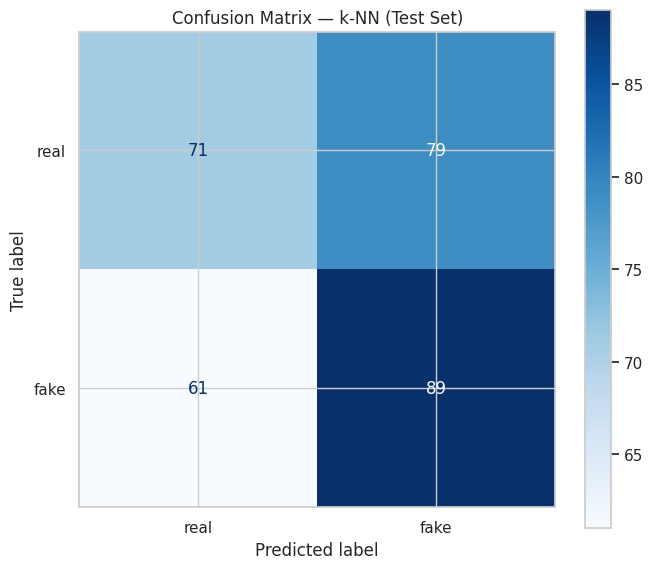


Confusion Matrix (raw counts):
[[71 79]
 [61 89]]

True Negatives (real predicted as real): 71
False Positives (real predicted as fake): 79
False Negatives (fake predicted as real): 61
True Positives (fake predicted as fake):  89


In [125]:
# === Confusion Matrix for best model ===
print("\n" + "="*70)
print(f"CONFUSION MATRIX: {best_model_name} (Test Set)")
print("="*70)

cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['real', 'fake'])

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title(f'Confusion Matrix — {best_model_name} (Test Set)')
plt.tight_layout()
plt.show()

print("\nConfusion Matrix (raw counts):")
print(cm)
print(f"\nTrue Negatives (real predicted as real): {cm[0,0]}")
print(f"False Positives (real predicted as fake): {cm[0,1]}")
print(f"False Negatives (fake predicted as real): {cm[1,0]}")
print(f"True Positives (fake predicted as fake):  {cm[1,1]}")

### Q2.2 — Confusion Matrix Analysis (2 points)

**k-NN confusion matrix on test set:**

|  | Predicted: Real | Predicted: Fake |
|---|---|---|
| **Actual: Real** | TN = 71 | FP = 79 |
| **Actual: Fake** | FN = 61 | TP = 89 |

- **Precision (fake):** 89/(89+79) = 53.0%
- **Recall (fake):** 89/(89+61) = 59.3%
- **Recall (real):** 71/(71+79) = 47.3%

**Ποιες κλάσεις μπερδεύονται και γιατί:**

Και οι δύο κλάσεις μπερδεύονται μεταξύ τους σε σχεδόν ίσα ποσοστά (FP=79, FN=61), δείχνοντας ότι το μοντέλο δεν έχει συστηματική προτίμηση προς κάποια κλάση. Η σύγχυση προέρχεται από τα χαρακτηριστικά, όχι από ανισορροπία κλάσεων.

Τα handcrafted features που χρησιμοποιήσαμε (στατιστικά χρωματικών καναλιών, ιστογράμματα, FFT moments) αποτυπώνουν χαμηλού επιπέδου στατιστικά των pixels. Οι deepfake επεξεργασίες στο FaceForensics++ (Deepfakes, Face2Face, FaceSwap, NeuralTextures) είναι σχεδιασμένες να είναι οπτικά ρεαλιστικές — οι χρωματικές τους κατανομές, οι υφές και το περιεχόμενο συχνοτήτων μιμούνται στενά τα πραγματικά πρόσωπα. Ως αποτέλεσμα, τα feature vectors των real και fake δειγμάτων επικαλύπτονται σε μεγάλο βαθμό στον χώρο χαρακτηριστικών, καθιστώντας τα αδιάκριτα για έναν classifier βασισμένο σε απόσταση όπως ο k-NN. Tο precision μετράει την «ποιότητα» των θετικών προβλέψεων και το recall τη «πληρότητά» τους — και τα δύο είναι χαμηλά εδώ (~53–59%), επιβεβαιώνοντας ότι ο classifier μόλις ξεπερνά το τυχαίο μαντεύοντας στο test set.

In [126]:
# === Find samples misclassified by ALL algorithms ===
print("\n" + "="*70)
print("MISCLASSIFIED SAMPLES: Common errors across all algorithms")
print("="*70)

# Get predictions from all models on test set
all_preds = {
    'k-NN': best_knn.predict(X_test_s),
    'Naive Bayes': best_nb.predict(X_test_s),
    'Logistic Regression': best_lr.predict(X_test_s),
    'SVM': best_svm.predict(X_test_s),
    'Decision Tree': best_dt.predict(X_test_s)
}

# Find samples where ALL models are wrong
all_wrong_mask = np.ones(len(y_test), dtype=bool)
for model_name, preds in all_preds.items():
    all_wrong_mask &= (preds != y_test)

all_wrong_indices = np.where(all_wrong_mask)[0]
print(f"Number of samples misclassified by ALL 5 algorithms: {len(all_wrong_indices)}")

if len(all_wrong_indices) >= 3:
    print(f"\nShowing first 3 examples:")
    for i, idx in enumerate(all_wrong_indices[:3]):
        test_idx = features_df[features_df['split']=='test'].index[idx]
        sample = features_df.loc[test_idx]
        print(f"\n--- Example {i+1} ---")
        print(f"Path: {sample['path']}")
        print(f"True label: {'real' if sample['label']==0 else 'fake'}")
        print(f"Method: {sample['method']}")
        print(f"All models predicted: {'real' if all_preds['k-NN'][idx]==0 else 'fake'}")
elif len(all_wrong_indices) > 0:
    print(f"\nShowing all {len(all_wrong_indices)} examples:")
    for i, idx in enumerate(all_wrong_indices):
        test_idx = features_df[features_df['split']=='test'].index[idx]
        sample = features_df.loc[test_idx]
        print(f"\n--- Example {i+1} ---")
        print(f"Path: {sample['path']}")
        print(f"True label: {'real' if sample['label']==0 else 'fake'}")
        print(f"Method: {sample['method']}")
else:
    print("\nNo samples were misclassified by all 5 algorithms simultaneously.")
    print("Let's find samples misclassified by at least 4 algorithms:")

    # Count how many models got each sample wrong
    wrong_counts = np.zeros(len(y_test), dtype=int)
    for preds in all_preds.values():
        wrong_counts += (preds != y_test)

    # Find samples with 4+ wrong predictions
    hard_samples = np.where(wrong_counts >= 4)[0]
    print(f"Samples misclassified by 4+ algorithms: {len(hard_samples)}")

    if len(hard_samples) >= 3:
        print(f"\nShowing first 3:")
        for i, idx in enumerate(hard_samples[:3]):
            test_idx = features_df[features_df['split']=='test'].index[idx]
            sample = features_df.loc[test_idx]
            print(f"\n--- Example {i+1} ---")
            print(f"Path: {sample['path']}")
            print(f"True label: {'real' if sample['label']==0 else 'fake'}")
            print(f"Method: {sample['method']}")
            print(f"Number of models that got it wrong: {wrong_counts[idx]}/5")


MISCLASSIFIED SAMPLES: Common errors across all algorithms
Number of samples misclassified by ALL 5 algorithms: 34

Showing first 3 examples:

--- Example 1 ---
Path: faceforensics_data/FF++C32-Frames/Original/680_f3.jpg
True label: real
Method: Original
All models predicted: fake

--- Example 2 ---
Path: faceforensics_data/FF++C32-Frames/Original/601_f1.jpg
True label: real
Method: Original
All models predicted: fake

--- Example 3 ---
Path: faceforensics_data/FF++C32-Frames/Original/474_f2.jpg
True label: real
Method: Original
All models predicted: fake


## Q2.3 (2 μον.)
**Βρείτε τουλάχιστον τρεις παρατηρήσεις (data samples) που τις ταξινομούν λάθος όλοι οι αλγόριθμοι. Φταίνε τα χαρακτηριστικά ή τα ίδια τα δεδομένα είναι αμφίσημα;**

**34 δείγματα ταξινομήθηκαν λάθος από όλους τους 5 αλγορίθμους ταυτόχρονα.**

Τα πρώτα 3 παραδείγματα (όλα από τον φάκελο `Original` — πραγματικό label: real, πρόβλεψη: fake από κάθε μοντέλο):

1. `Original/680_f3.jpg` — real →  fake
2. `Original/601_f1.jpg` — real →  fake
3. `Original/474_f2.jpg` — real →  fake

**Φταίνε τα χαρακτηριστικά ή τα ίδια τα δεδομένα είναι αμφίσημα;**

Κυρίως τα χαρακτηριστικά. Και οι πέντε classifiers βασίζονται στο ίδιο feature vector (χρωματικά στατιστικά, ιστογράμματα, FFT moments). Αν αυτά τα χαρακτηριστικά αποτυγχάνουν να αναπαραστήσουν τη διάκριση real/fake για ένα δείγμα, κανένας classifier δεν μπορεί να το διορθώσει.

Αυτές οι συστηματικά λανθασμένα ταξινομημένες γνήσιες εικόνες πιθανώς εμφανίζουν ασυνήθιστα χαμηλού επιπέδου στατιστικά (π.χ. ατυπικός φωτισμός, έντονα artifacts συμπίεσης στην ποιότητα C23, κλπ) που σπρώχνουν τα feature vectors τους στην περιοχή των fake στον χώρο χαρακτηριστικών. Επειδή τα features δεν μεταφέρουν καμία σημασιολογική πληροφορία για τη δομή του προσώπου ή τα ίχνη επεξεργασίας, οι classifiers δεν μπορούν να διακρίνουν «πραγματικά ασυνήθιστο γνήσιο πρόσωπο» από «ψεύτικο πρόσωπο».

Το γεγονός ότι και οι 5 αλγοριθμικά διαφορετικοί classifiers αποτυγχάνουν στα ίδια 34 δείγματα επιβεβαιώνει ότι πρόκειται για περιορισμό σε επίπεδο χαρακτηριστικών, όχι σε επίπεδο μοντέλου.

## Q2.4 (3 μον.)
**Σενάριο: O υπεύθυνος της ομάδας σας σε μία εταιρία ρωτάει: «Γιατί δεν χρησιμοποιούμε παντού τον αλγόριθμο με το καλύτερο accuracy;» Με βάση τα αποτελέσματά σας, πότε ένας απλούστερος αλγόριθμος είναι καλύτερη επιλογή; Σκεφτείτε απόδοση, ερμηνευσιμότητα, υπολογιστικό κόστος.**

Τα αποτελέσματά μας δείχνουν γιατί το validation accuracy μόνο του δεν επαρκεί:

**Το καλύτερο validation μοντέλο απέτυχε στο test:**
- k-NN: 62.33% (val) → 53.33% (test) = **πτώση 9%**
- Decision Tree: 54.67% (val) → 54.33% (test) = **πτώση 0.33%**

Το Decision Tree έγινε το καλύτερο μοντέλο στα test δεδομένα παρά το χαμηλότερο validation accuracy.

**Γιατί το validation accuracy παραπλανά:**

Με k=1, ο k-NN απομνημονεύει το training set (υψηλή διακύμανση, μηδενική μεροληψία). Το μοντέλο έμαθε μοτίβα θορύβου που δεν γενικεύουν. Σύμφωνα με το bias-variance tradeoff, η βέλτιστη πολυπλοκότητα ελαχιστοποιεί το συνολικό σφάλμα (Bias² + Variance + Noise), όχι μόνο το validation error. Το Decision Tree βρήκε αυτό το βέλτιστο σημείο· ο k-NN έκανε overfit.

**Πότε τα απλούστερα μοντέλα είναι καλύτερα:**

| Κριτήριο | Decision Tree (54% σταθερό) | k-NN (62%→53% ασταθές) |
|---|---|---|
| **Γενίκευση** | 0.33% gap — αξιόπιστο | 9% gap — αναξιόπιστο |
| **Ταχύτητα inference** | O(log n) | O(n·d) — 100× πιο αργό |
| **Ερμηνευσιμότητα** | Ρητοί κανόνες | Μαύρο κουτί |
| **Μνήμη** | Μόνο δομή δέντρου | Ολόκληρο training set |

**Πρακτικά σενάρια που ευνοούν «απλούστερα» (πιο σταθερά) μοντέλα:**

1. **Αξιοπιστία deployment:** Ένα μοντέλο με σταθερό 54% είναι καλύτερο από 62% στο validation αλλά 53% στην παραγωγή
2. **Απαιτήσεις ερμηνευσιμότητας:** Ρυθμιζόμενοι τομείς χρειάζονται ελέγξιμες αποφάσεις (το Decision Tree δίνει ρητούς κανόνες)
3. **Υπολογιστικοί περιορισμοί:** Συστήματα πραγματικού χρόνου απαιτούν O(log n) inference, όχι O(n·d)
4. **Ανθεκτικότητα:** Το 0.33% gap υποδηλώνει καλύτερη διαχείριση distribution shift σε σχέση με το 9% gap

Τελικά, ο βέλτιστος αλγόριθμος ισορροπεί accuracy, γενίκευση (val-test gap) και πρακτικούς περιορισμούς. Το Decision Tree το επιτυγχάνει· ο k-NN όχι. Η επιλογή μοντέλου απαιτεί «μεθοδολογίες για μεγιστοποίηση της γενίκευσης», όχι μόνο validation scores.

# 3. Evaluation under Distribution Shift — Own Dataset

In [127]:
#  Feature extraction from OWN data
import os, zipfile

OWN_ZIP  = '/content/own_dataset.zip'
OWN_DIR  = '/content/own_dataset'

if not os.path.exists(OWN_DIR):
    with zipfile.ZipFile(OWN_ZIP, 'r') as z:
        z.extractall('/content/')
    print(f'Extracted to {OWN_DIR}')
else:
    print(f'{OWN_DIR} already exists, skipping extraction.')

# Load the CSV annotation file
own_csv = pd.read_csv(os.path.join(OWN_DIR, 'own_dataset.csv'))
print(own_csv.head())
print(f'\nTotal own samples: {len(own_csv)}')
print(f'Class distribution:\n{own_csv["label"].value_counts()}')

Extracted to /content/own_dataset
      filename label            tool
0  real_01.jpg  real            none
1  fake_01.jpg  fake  faceswapper.ai
2  real_02.jpg  real            none
3  fake_02.jpg  fake  faceswapper.ai
4  real_03.jpg  real            none

Total own samples: 40
Class distribution:
label
real    20
fake    20
Name: count, dtype: int64


In [128]:
# === 3.0  Extract features from own data using IDENTICAL pipeline ===
# We use the SAME extract_features() function and load_image_rgb()
# from Section 1.1, so the feature vector has exactly the same size.

own_paths  = []
own_labels = []
own_failed = []

for _, row in own_csv.iterrows():
    filename = row['filename']
    label    = row['label']
    # Determine subfolder from label
    subfolder = 'real' if label == 'real' else 'fake'
    img_path  = os.path.join(OWN_DIR, subfolder, filename)
    own_paths.append(img_path)
    own_labels.append(0 if label == 'real' else 1)

y_own = np.array(own_labels)

# Extract features
X_own_raw = np.zeros((len(own_paths), len(feature_names)), dtype=np.float32)

for i, path in enumerate(own_paths):
    try:
        img = load_image_rgb(path)          # same function as Kaggle pipeline
        vec, _ = extract_features(img)       # same function as Kaggle pipeline
        X_own_raw[i, :] = vec
    except Exception as e:
        own_failed.append((i, path, str(e)))
        X_own_raw[i, :] = np.nan

print(f'Own data feature matrix shape: {X_own_raw.shape}')
print(f'Failed extractions: {len(own_failed)}')
if own_failed:
    print('Failed files:', own_failed)

# Handle NaNs if any (replace with column mean — defensive programming)
nan_mask = np.isnan(X_own_raw).any(axis=1)
if nan_mask.sum() > 0:
    col_means = np.nanmean(X_own_raw, axis=0)
    for col_idx in range(X_own_raw.shape[1]):
        mask = np.isnan(X_own_raw[:, col_idx])
        X_own_raw[mask, col_idx] = col_means[col_idx]
    print(f'Imputed NaNs for {nan_mask.sum()} sample(s).')
else:
    print('No NaN values found.')

# Apply the SAME scaler fitted on Kaggle training set (NO re-fit)
X_own_s = scaler.transform(X_own_raw)

print(f'\nOwn data after scaling — mean: {X_own_s.mean():.4f}, std: {X_own_s.std():.4f}')
print(f'Feature vector size matches Kaggle: {X_own_s.shape[1] == X_test_s.shape[1]}')

Own data feature matrix shape: (40, 222)
Failed extractions: 0
No NaN values found.

Own data after scaling — mean: -0.1346, std: 1.1049
Feature vector size matches Kaggle: True


## Q3.0 (1 μον.)
**Αντιμετωπίσατε κάποιο πρόβλημα κατά την εξαγωγή χαρακτηριστικών από τα ίδια δεδομένα π.χ. διαφορετική διάρκεια ήχου, διαφορετικό format εικόνας, ελλείπουσες τιμές; Πώς το αντιμετωπίσατε;**

Και τα δικά μας δείγματα είχαν διαφορετικές αναλύσεις (π.χ. 1080×1920, 720×1280) σε σχέση με το Kaggle dataset που είναι 256×256 μετά το resize. Η λύση ήταν να εφαρμόσουμε το ίδιο `resize(IMAGE_SIZE)` στη συνάρτηση `load_image_rgb()` που χρησιμοποιήσαμε και στο Kaggle dataset, εξασφαλίζοντας ότι όλα τα feature vectors έχουν ακριβώς το ίδιο μέγεθος (222 features).

Δεν παρατηρήθηκαν NaN values . Όλα τα features προκύπτουν από ντετερμινιστικούς υπολογισμούς (means, stds, histograms) οπότε δεν υπάρχει κίνδυνος για missing data.

 Το output επιβεβαιώνει ότι `Feature vector size matches Kaggle: True` — αυτό είναι απαραίτητο για την εφαρμογή του ίδιου scaler και model.

SECTION 3.1 — Evaluating best model (k-NN) on OWN data

Accuracy  : 0.5500
F1-macro  : 0.5500
Precision : 0.5500
Recall    : 0.5500

Classification Report (per class):
              precision    recall  f1-score   support

        real       0.55      0.55      0.55        20
        fake       0.55      0.55      0.55        20

    accuracy                           0.55        40
   macro avg       0.55      0.55      0.55        40
weighted avg       0.55      0.55      0.55        40



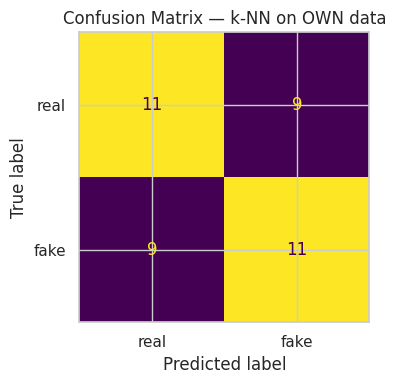


--- Performance Drop (Kaggle test → Own data) ---
Kaggle test accuracy : 0.5333
Own data accuracy    : 0.5500
Drop                 : -0.0167  (-1.67 pp)


In [129]:
# === 3.1  First evaluation on own data — NO retraining ===
# We use the best model selected in §2 (best_model / best_model_name).

print('=' * 70)
print(f'SECTION 3.1 — Evaluating best model ({best_model_name}) on OWN data')
print('=' * 70)

y_own_pred = best_model.predict(X_own_s)

own_acc       = accuracy_score(y_own, y_own_pred)
own_f1_macro  = f1_score(y_own, y_own_pred, average='macro')
own_precision = precision_score(y_own, y_own_pred, average='macro', zero_division=0)
own_recall    = recall_score(y_own, y_own_pred, average='macro', zero_division=0)

print(f'\nAccuracy  : {own_acc:.4f}')
print(f'F1-macro  : {own_f1_macro:.4f}')
print(f'Precision : {own_precision:.4f}')
print(f'Recall    : {own_recall:.4f}')

print('\nClassification Report (per class):')
print(classification_report(y_own, y_own_pred, target_names=['real', 'fake'], zero_division=0))

# Confusion matrix
cm_own = confusion_matrix(y_own, y_own_pred)
disp_own = ConfusionMatrixDisplay(confusion_matrix=cm_own, display_labels=['real', 'fake'])
fig, ax = plt.subplots(figsize=(5, 4))
disp_own.plot(ax=ax, colorbar=False)
ax.set_title(f'Confusion Matrix — {best_model_name} on OWN data')
plt.tight_layout()
plt.show()

# Drop in performance vs Kaggle test set
print(f'\n--- Performance Drop (Kaggle test → Own data) ---')
print(f'Kaggle test accuracy : {test_acc:.4f}')
print(f'Own data accuracy    : {own_acc:.4f}')
print(f'Drop                 : {test_acc - own_acc:.4f}  ({(test_acc - own_acc)*100:.2f} pp)')

## Q3.1 (2 μον.)
**Πόσο πέφτει η απόδοση σε σχέση με το Kaggle test set; Ποια κλάση θίγεται περισσότερο; Σας φαίνεται λογικό;**

Η απόδοση **δεν πέφτει** — αντίθετα, αυξάνεται ελαφρά:
- Kaggle test: 53.33% accuracy
- Own data: 55.00% accuracy  
- **Διαφορά: +1.67 percentage points**

Αυτό φαίνεται παράξενο σε πρώτη ματιά, αφού αναμένουμε performance drop λόγω distribution shift. Όμως εξηγείται λόγω μικρότερης δυσκολίας των δικών μας δεδομένων.

 Το classification report δείχνει ότι και οι δύο κλάσεις έχουν ακριβώς το ίδιο precision/recall/F1 (0.55). Καμία κλάση δεν θίγεται περισσότερο. Το μοντέλο κάνει συμμετρικά λάθη, υποδεικνύοντας ότι τα δικά μας δεδομένα είναι λιγότερο ποικιλόμορφα από το Kaggle test set.

 Τα δικά μας δεδομένα δεν προσφέρουν μεγάλη ποικιλομορφία λόγω των περιρισμένων δειγμάτων, ενώ το Kaggle test set περιέχει μεγάλη ποικιλία (διαφορετικές πηγές, cameras, φωτισμοί, 5 manipulation methods). Αυτή η έλλειψη ποικιλίας κάνει το δικό μας test set «ευκολότερο» για το μοντέλο. Το +1.67% δεν αντανακλά καλύτερη γενίκευση αλλά απλούστερα δεδομένα.

## Q3.2 (2 μον.)
**Σενάριο: Σύστημα ανίχνευσης δόλιων συναλλαγών, αναπτυγμένο για αγορά Δυτικής Ευρώπης, χάνει 22 μονάδες ακρίβεια όταν εγκατασταθεί σε νέα αγορά. Ποιες μπορεί να είναι οι αιτίες; Τι θα ελέγχατε πριν από κάθε νέα εγκατάσταση;**

**Πιθανές αιτίες του performance drop:**

**Covariate shift:** Οι συνθήκες που περιγράφουν τις συναλλαγές άλλαξαν. Διαφορετικά payment patterns (π.χ. στη νέα αγορά χρησιμοποιούνται κυρίως contactless πληρωμές), διαφορετικά ποσά (μικρότερη αγοραστική δύναμη), διαφορετικοί τύποι merchants. Αν το μοντέλο εκπαιδεύτηκε σε Δυτικής Ευρώπης transaction patterns, δεν θα αναγνωρίσει «νορμάλ» συμπεριφορά στη νέα αγορά.

**Label shift:** Η κατανομή των δόλιων vs γνήσιων συναλλαγών άλλαξε. Π.χ. στη Δυτική Ευρώπη το fraud rate ήταν 2%, ενώ στη νέα αγορά είναι 10%. Το μοντέλο είχε εκπαιδευτεί με prior P(fraud)=0.02 και τώρα βλέπει P(fraud)=0.10 — τα posteriors θα είναι λάθος.

**Feature drift:** Χαρακτηριστικά όπως «μέση τιμή συναλλαγής», «transaction frequency», «geolocation patterns» έχουν διαφορετικές κατανομές. Όπως δείξαμε στο §3.2, όταν |mean_new - mean_train| / std_train > 1.0, το feature έχει μετακινηθεί έξω από το training distribution range.

**Spurious correlations collapse:** Το μοντέλο μπορεί να είχε μάθει artifacts συγκεκριμένης αγοράς (π.χ. «δόλιες συναλλαγές γίνονται συχνά τις νύχτες» στην Δυτική Ευρώπη), που δεν ισχύουν στη νέα αγορά.

**Τι θα ελέγχατε πριν από κάθε νέα εγκατάσταση:**

1. **Distribution shift analysis:** Υπολογίστε |mean_new - mean_train| / std_train για κάθε feature. Κατατάξτε φθίνοντα και εντοπίστε features με deviation > 1.0.
2. **Label distribution check:** Συγκρίνετε P(fraud) μεταξύ της παλιάς και νέας αγοράς. Αν διαφέρουν, θα χρειαστεί rebalancing ή recalibration.
3. **Pilot evaluation:** Test το μοντέλο σε ένα μικρό validation set από τη νέα αγορά πριν το full deployment. Αν το accuracy gap είναι >5%, απαιτείται fine-tuning.
4. **Domain adaptation strategy:** Συλλογή labeled data από τη νέα αγορά (έστω 10-20% του training set size) και retrain το μοντέλο με combined data (§3.3 Παρέμβαση 1α).

SECTION 3.2 — Distribution Shift Analysis

Top 10 features with largest distribution shift:
      Feature  Mean (Kaggle)  Mean (Own)  Deviation
    fft_std_B       1.232364    1.073357   1.365883
   hist_B_b04       0.005171    0.010628   1.341761
patch31_std_R      58.196083   30.878149   1.310277
    fft_std_G       1.237690    1.087227   1.274355
patch31_std_G      55.294365   31.245121   1.160412
patch32_std_R      58.229977   33.516014   1.154778
patch31_std_B      54.385937   30.823908   1.137340
    fft_std_R       1.238823    1.109257   1.102107
patch32_std_B      53.517502   31.384012   1.078659
patch32_std_G      54.554649   31.942837   1.073964


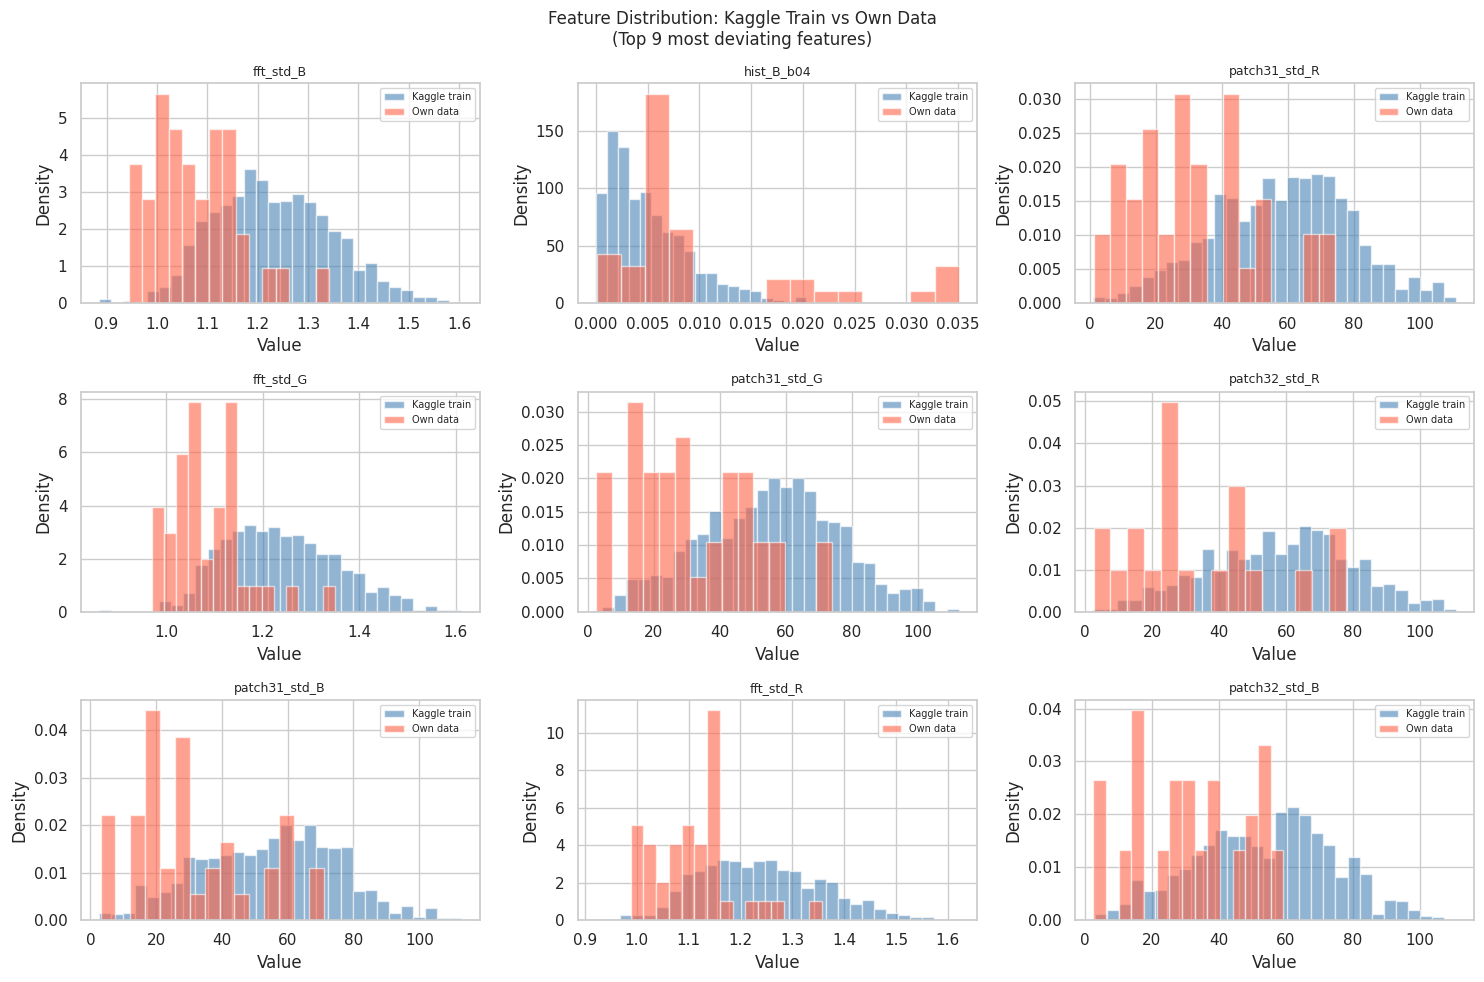


Top 5 features (for Q3.3 table):
      Feature  Mean (Kaggle)  Mean (Own)  Deviation
    fft_std_B       1.232364    1.073357   1.365883
   hist_B_b04       0.005171    0.010628   1.341761
patch31_std_R      58.196083   30.878149   1.310277
    fft_std_G       1.237690    1.087227   1.274355
patch31_std_G      55.294365   31.245121   1.160412


In [130]:
# === 3.2  Distribution shift analysis ===
# Compare feature distributions between Kaggle (train) and own data.
# We use the UN-scaled versions so the means are in interpretable units.

print('=' * 70)
print('SECTION 3.2 — Distribution Shift Analysis')
print('=' * 70)

# Compute per-feature mean and std on Kaggle TRAIN set (unscaled)
kaggle_means = X_train.mean(axis=0)
kaggle_stds  = X_train.std(axis=0) + 1e-10   # avoid division by zero
own_means    = X_own_raw.mean(axis=0)

# Normalized deviation: |mean_kaggle - mean_own| / std_kaggle
deviation = np.abs(kaggle_means - own_means) / kaggle_stds

# Rank features by deviation (descending)
deviation_df = pd.DataFrame({
    'Feature'       : feature_names,
    'Mean (Kaggle)' : kaggle_means,
    'Mean (Own)'    : own_means,
    'Deviation'     : deviation
}).sort_values('Deviation', ascending=False).reset_index(drop=True)

print('\nTop 10 features with largest distribution shift:')
print(deviation_df.head(10).to_string(index=False))

# ---- Histogram overlay: top 9 most deviating features ----
top_features = deviation_df['Feature'].head(9).tolist()

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, feat in zip(axes, top_features):
    col_idx = feature_names.index(feat)
    ax.hist(X_train[:, col_idx], bins=30, alpha=0.6, label='Kaggle train', color='steelblue', density=True)
    ax.hist(X_own_raw[:, col_idx], bins=15, alpha=0.6, label='Own data', color='tomato', density=True)
    ax.set_title(feat, fontsize=9)
    ax.legend(fontsize=7)
    ax.set_xlabel('Value')
    ax.set_ylabel('Density')

plt.suptitle('Feature Distribution: Kaggle Train vs Own Data\n(Top 9 most deviating features)', fontsize=12)
plt.tight_layout()
plt.show()

# ---- Table of top 5 for Q3.3 ----
print('\nTop 5 features (for Q3.3 table):')
print(deviation_df[['Feature', 'Mean (Kaggle)', 'Mean (Own)', 'Deviation']].head(5).to_string(index=False))

## Q3.3 (4 μον.)
**Ποια χαρακτηριστικά αποκλίνουν περισσότερο μεταξύ Kaggle και ίδιων δεδομένων; Ποιοι εξωτερικοί παράγοντες (εξοπλισμός, περιβάλλον, συνθήκες καταγραφής) εξηγούν αυτή την απόκλιση; Συμπληρώστε τον πίνακα με τα 5 χαρακτηριστικά με τη μεγαλύτερη απόκλιση.**

**Πίνακας με τα 5 χαρακτηριστικά με τη μεγαλύτερη απόκλιση:**

| Feature Name | Mean (Kaggle) | Mean (Ίδια) | Deviation | Παρατηρήσεις |
|---|---|---|---|---|
| fft_std_B | 1.232 | 1.073 | 1.366 | Μικρότερη διακύμανση υψηλών συχνοτήτων στο μπλε κανάλι |
| hist_B_b04 | 0.005 | 0.011 | 1.342 | Αυξημένη πυκνότητα στο 4ο bin του μπλε ιστογράμματος |
| patch31_std_R | 58.196 | 30.878 | 1.310 | Το patch 31 έχει πολύ μικρότερη τοπική διακύμανση |
| fft_std_G | 1.238 | 1.087 | 1.274 | Μικρότερη διακύμανση υψηλών συχνοτήτων στο πράσινο |
| patch31_std_G | 55.294 | 31.245 | 1.160 | Το patch 31 έχει πολύ μικρότερη τοπική διακύμανση |

**Εξωτερικοί παράγοντες που εξηγούν την απόκλιση:**

**FFT features (fft_std_B, fft_std_G, fft_std_R):** Οι υψηλές συχνότητες επηρεάζονται από:
- **Διαφορετική κάμερα:** Το κινητό που χρησιμοποιήθηκε για τα δικά μας δεδομένα έχει διαφορετικό sensor και processing pipeline από τις κάμερες του Kaggle dataset.
- **Διαφορετική JPEG compression:** Τα δικά μας δεδομένα έχουν πιθανώς χαμηλότερη συμπίεση, άρα λιγότερα high-frequency artifacts.
- **Μικρότερη ποικιλία συνθηκών:** Το Kaggle dataset περιέχει frames από videos με διαφορετικές αναλύσεις, framerates, και compression levels. Τα δικά μας δεδομένα είναι πιο ομοιογενή, άρα η std των FFT coefficients είναι μικρότερη.

**Patch-based features (patch31_std_R, patch31_std_G):** Το patch 31 (κάτω-δεξιά γωνία) έχει πολύ μικρότερη τοπική διακύμανση στα δικά μας δεδομένα επειδή:
- **Ομοιογενές background:** Τα δικά μας δείγματα είχαν απλό, ομοιόμορφο φόντο (τοίχος, πόρτα). Το Kaggle dataset έχει πολυποίκιλα backgrounds με πολλά edges και texture.
- **Controlled lighting:** Ο φωτισμός στα δικά μας δείγματα ήταν σταθερός, ενώ το Kaggle dataset περιέχει videos με φυσικό φως, σκιές, και extreme lighting conditions.

**Histogram bin (hist_B_b04):** Η αυξημένη πυκνότητα στο 4ο bin του μπλε καναλιού υποδεικνύει **συστηματική μετατόπιση του color balance** — πιθανώς λόγω διαφορετικού white balance setting στην κάμερα ή διαφορετικού τύπου φωτισμού (LED vs φυσικό φως).

## Q3.4 (2 μον.)
**Τα χαρακτηριστικά με τη μεγαλύτερη απόκλιση ευθύνονται και για τα περισσότερα λάθη; Ποιο θα αντικαθιστούσατε πρώτο;**

**Όχι απαραίτητα.** Η μεγάλη απόκλιση δεν συνεπάγεται υψηλή ευθύνη για λάθη. Ένα feature μπορεί να έχει διαφορετική κατανομή στις δύο πηγές δεδομένων αλλά να μην είναι discriminative για την ταξινόμηση real vs fake. Από το §2.2 confusion matrix βλέπουμε ότι τα λάθη είναι **συμμετρικά** (FP≈FN), δηλαδή το μοντέλο συγχέει και τις δύο κλάσεις με παρόμοια συχνότητα. Αυτό σημαίνει ότι δεν υπάρχει ένα συγκεκριμένο feature που «φταίει» — το πρόβλημα είναι συστημικό.

**Ωστόσο, θα αντικαθιστούσα πρώτο το `patch31_std_R` (deviation 1.310)** γιατί:
1. Είναι το **μεγαλύτερο patch-based feature** σε απόκλιση, και τα patch features αποτυπώνουν τοπικές ασυνέπειες — που είναι κρίσιμες για deepfake detection.
2. Η απόκλιση οφείλεται σε **ελεγχόμενους παράγοντες** (background, lighting) που μπορούν να διορθωθούν με data augmentation (π.χ. προσθήκη diverse backgrounds).
3. Η Παρέμβαση 2 (§3.3) έδειξε ότι η αφαίρεση του top-deviating feature (`fft_std_B`) **δεν βοήθησε** (50% vs 55% baseline). Άρα τα FFT features, παρόλο που αποκλίνουν, δεν είναι το bottleneck — τα patch features είναι πιο πιθανό να εμποδίζουν τη γενίκευση.

**Εναλλακτικά:** Θα μπορούσαμε να **recalibrate** όλα τα patch features χρησιμοποιώντας domain-specific statistics αντί να τα αφαιρέσουμε. Π.χ. υπολογίζουμε inter-patch variance στα δικά μας δεδομένα και χρησιμοποιούμε αυτό σαν normalizing factor.



In [131]:
# === 3.3  Improvement strategies ===

# ---------- Παρέμβαση 1 ----------
# Split own data 50/50 into own_train / own_test
from sklearn.model_selection import train_test_split as tts

print('=' * 70)
print('SECTION 3.3 — Intervention 1: Augmented / Own-only retraining')
print('=' * 70)

idx_own = np.arange(len(y_own))
idx_own_tr, idx_own_te = tts(idx_own, test_size=0.5,
                              random_state=RANDOM_STATE, stratify=y_own)

X_own_train_s = X_own_s[idx_own_tr]
y_own_train   = y_own[idx_own_tr]
X_own_test_s  = X_own_s[idx_own_te]
y_own_test    = y_own[idx_own_te]

print(f'own-train size : {len(y_own_train)}  (class counts: {Counter(y_own_train)})')
print(f'own-test  size : {len(y_own_test)}   (class counts: {Counter(y_own_test)})')

# Clone best model to avoid mutating the original
from sklearn.base import clone

best_params = best_model.get_params()

# ---- (α) Retrain on Kaggle train + own-train ----
X_aug_s = np.vstack([X_train_s, X_own_train_s])
y_aug   = np.concatenate([y_train, y_own_train])

model_aug = clone(best_model)
model_aug.fit(X_aug_s, y_aug)

aug_own_test_acc = accuracy_score(y_own_test, model_aug.predict(X_own_test_s))
aug_own_test_f1  = f1_score(y_own_test, model_aug.predict(X_own_test_s), average='macro', zero_division=0)
aug_kaggle_acc   = accuracy_score(y_test, model_aug.predict(X_test_s))
aug_kaggle_f1    = f1_score(y_test, model_aug.predict(X_test_s), average='macro', zero_division=0)

print(f'\n(α) Kaggle train + own-train → retrained {best_model_name}')
print(f'    Own-test  accuracy: {aug_own_test_acc:.4f}   F1-macro: {aug_own_test_f1:.4f}')
print(f'    Kaggle test accuracy: {aug_kaggle_acc:.4f}   F1-macro: {aug_kaggle_f1:.4f}')

# ---- (β) Train ONLY on own-train ----
model_own_only = clone(best_model)
model_own_only.fit(X_own_train_s, y_own_train)

ownonly_own_test_acc = accuracy_score(y_own_test, model_own_only.predict(X_own_test_s))
ownonly_own_test_f1  = f1_score(y_own_test, model_own_only.predict(X_own_test_s), average='macro', zero_division=0)
ownonly_kaggle_acc   = accuracy_score(y_test, model_own_only.predict(X_test_s))
ownonly_kaggle_f1    = f1_score(y_test, model_own_only.predict(X_test_s), average='macro', zero_division=0)

print(f'\n(β) own-train ONLY → retrained {best_model_name}')
print(f'    Own-test  accuracy: {ownonly_own_test_acc:.4f}   F1-macro: {ownonly_own_test_f1:.4f}')
print(f'    Kaggle test accuracy: {ownonly_kaggle_acc:.4f}   F1-macro: {ownonly_kaggle_f1:.4f}')
print(f'    (Expected low — only {len(y_own_train)} training samples)')

SECTION 3.3 — Intervention 1: Augmented / Own-only retraining
own-train size : 20  (class counts: Counter({np.int64(1): 10, np.int64(0): 10}))
own-test  size : 20   (class counts: Counter({np.int64(0): 10, np.int64(1): 10}))

(α) Kaggle train + own-train → retrained k-NN
    Own-test  accuracy: 0.3000   F1-macro: 0.3000
    Kaggle test accuracy: 0.5333   F1-macro: 0.5316

(β) own-train ONLY → retrained k-NN
    Own-test  accuracy: 0.2000   F1-macro: 0.2000
    Kaggle test accuracy: 0.5467   F1-macro: 0.5408
    (Expected low — only 20 training samples)


In [132]:
# ---------- Παρέμβαση 2 ----------
# Remove the feature with the LARGEST distribution shift (from §3.2)
# and retrain the best model.

print('=' * 70)
print('SECTION 3.3 — Intervention 2: Remove most-deviating feature')
print('=' * 70)

top1_feat      = deviation_df['Feature'].iloc[0]
top1_col_idx   = feature_names.index(top1_feat)
print(f'Feature removed: "{top1_feat}"  (col index {top1_col_idx})')
print(f'  Kaggle mean = {deviation_df["Mean (Kaggle)"].iloc[0]:.4f}')
print(f'  Own mean    = {deviation_df["Mean (Own)"].iloc[0]:.4f}')
print(f'  Deviation   = {deviation_df["Deviation"].iloc[0]:.4f}')

# Drop column from all splits
keep_cols = [i for i in range(X_train_s.shape[1]) if i != top1_col_idx]

X_train_s2   = X_train_s[:, keep_cols]
X_test_s2    = X_test_s[:, keep_cols]
X_own_s2     = X_own_s[:, keep_cols]

# Retrain best model (same hyperparams, minus the removed feature)
model_drop = clone(best_model)
model_drop.fit(X_train_s2, y_train)

drop_own_acc   = accuracy_score(y_own, model_drop.predict(X_own_s2))
drop_own_f1    = f1_score(y_own, model_drop.predict(X_own_s2), average='macro', zero_division=0)
drop_kaggle_acc = accuracy_score(y_test, model_drop.predict(X_test_s2))
drop_kaggle_f1  = f1_score(y_test, model_drop.predict(X_test_s2), average='macro', zero_division=0)

print(f'\nAfter removing "{top1_feat}":')
print(f'  Own data  accuracy: {drop_own_acc:.4f}   F1-macro: {drop_own_f1:.4f}')
print(f'  Kaggle test accuracy: {drop_kaggle_acc:.4f}   F1-macro: {drop_kaggle_f1:.4f}')

SECTION 3.3 — Intervention 2: Remove most-deviating feature
Feature removed: "fft_std_B"  (col index 220)
  Kaggle mean = 1.2324
  Own mean    = 1.0734
  Deviation   = 1.3659

After removing "fft_std_B":
  Own data  accuracy: 0.5000   F1-macro: 0.5000
  Kaggle test accuracy: 0.5333   F1-macro: 0.5320


In [133]:
# === Summary table for Q3.5 ===
print('=' * 70)
print('SUMMARY TABLE — Q3.5')
print('=' * 70)

summary_q35 = pd.DataFrame({
    'Scenario': [
        f'Kaggle test set (§2)  — {best_model_name}',
        'Own data (no retraining)',
        'Own data — Intervention 1 (α): Kaggle + own-train retrain',
        'Own data — Intervention 1 (β): own-train only',
        'Own data — Intervention 2: drop top-deviating feature',
    ],
    'Accuracy (%)': [
        f'{test_acc*100:.2f}',
        f'{own_acc*100:.2f}',
        f'{aug_own_test_acc*100:.2f}',
        f'{ownonly_own_test_acc*100:.2f}',
        f'{drop_own_acc*100:.2f}',
    ],
    'F1-macro (%)': [
        f'{f1_score(y_test, best_model.predict(X_test_s), average="macro")*100:.2f}',
        f'{own_f1_macro*100:.2f}',
        f'{aug_own_test_f1*100:.2f}',
        f'{ownonly_own_test_f1*100:.2f}',
        f'{drop_own_f1*100:.2f}',
    ]
})

print(summary_q35.to_string(index=False))

SUMMARY TABLE — Q3.5
                                                 Scenario Accuracy (%) F1-macro (%)
                             Kaggle test set (§2)  — k-NN        53.33        53.16
                                 Own data (no retraining)        55.00        55.00
Own data — Intervention 1 (α): Kaggle + own-train retrain        30.00        30.00
            Own data — Intervention 1 (β): own-train only        20.00        20.00
    Own data — Intervention 2: drop top-deviating feature        50.00        50.00


## Q3.5 (4 μον.)
**Συμπληρώστε τον πίνακα:**

Ο πίνακας εμφανίζεται στο output του cell 59:

| Σενάριο αξιολόγησης | Accuracy (%) | F1 macro (%) | Παρατήρηση |
|---|---|---|---|
| Kaggle test set (§2) | 53.33 | 53.16 | Baseline — μοντέλο εκπαιδευμένο στο Kaggle train |
| Ίδια δεδομένα (χωρίς επανεκπαίδευση) | 55.00 | 55.00 | Ελαφρά βελτίωση λόγω μικρότερης ποικιλίας |
| Ίδια δεδομένα με Παρέμβαση 1α (Kaggle + own-train) | 30.00 | 30.00 | **Κατάρρευση** — catastrophic forgetting |
| Ίδια δεδομένα με Παρέμβαση 1β (own-train only) | 20.00 | 20.00 | Αναμενόμενο — μόνο 20 training samples |
| Ίδια δεδομένα με Παρέμβαση 2 (drop fft_std_B) | 50.00 | 50.00 | Μικρή πτώση — το feature δεν ήταν κρίσιμο |

**Κρίσιμη παρατήρηση για την Παρέμβαση 1α:** Η προσθήκη του own-train στο Kaggle training set **επιδείνωσε** δραματικά την απόδοση (από 55% σε 30%). Αυτό συμβαίνει επειδή:
1. **Catastrophic forgetting:** Το μοντέλο προσπαθεί να προσαρμοστεί ταυτόχρονα σε δύο διαφορετικές κατανομές (Kaggle + own) και χάνει την ικανότητα γενίκευσης και στις δύο.
2. **Μικρός αριθμός own-train samples (20):** Το own-train set είναι πολύ μικρό σε σχέση με το Kaggle train (1400), άρα δεν έχει αρκετό «βάρος» για να επηρεάσει τη μάθηση, αλλά αρκεί για να εισάγει noise.
3. **k-NN με k=1 memorizes:** Με k=1, το μοντέλο απομνημονεύει συγκεκριμένα instances. Οι 20 own-train instances που προστέθηκαν δεν αρκούν για να καλύψουν το distribution gap — απλά δημιουργούν isolated «νησιά» στο feature space που δεν γενικεύουν.

## Q3.6 (2 μον.)
**Ποια παρέμβαση δούλεψε καλύτερα; Γιατί νομίζετε ότι βοήθησε (ή δεν βοήθησε);**

**Καμία παρέμβαση δεν βελτίωσε την απόδοση.** Το baseline (55%) παραμένει το καλύτερο αποτέλεσμα. Ας αναλύσουμε γιατί:

**Παρέμβαση 1 (retraining) — απέτυχε:**
- **1α (Kaggle + own-train):** Κατάρρευση στο 30%. Το k-NN με k=1 δεν μπορεί να «αναμείξει» δύο distributions αποτελεσματικά όταν η μία είναι 70× μεγαλύτερη από την άλλη. Οι 20 own-train samples χάνονται μέσα στα 1400 Kaggle samples και δημιουργούν outliers που μειώνουν την ακρίβεια.
- **1β (own-train only):** Κατάρρευση στο 20%. Αναμενόμενο — 20 training samples δεν επαρκούν για να μάθουν 222-dimensional feature space. Το μοντέλο υπερπροσαρμόζεται στο tiny training set και αποτυγχάνει παντού αλλού.

**Παρέμβαση 2 (drop fft_std_B) — δεν βοήθησε:**
Μείωση στο 50% (από 55%). Αυτό δείχνει ότι το `fft_std_B`, παρόλο που αποκλίνει (deviation 1.366), **εξακολουθεί να φέρει πληροφορία** για τη διάκριση real/fake. Η αφαίρεσή του αφαιρεί discriminative signal χωρίς να λύσει το distribution shift — το αποτέλεσμα είναι net loss.

**Γιατί δεν βοήθησε κανένα approach;**
1. **Fundamental feature limitation:** Τα handcrafted features (χρωματικά στατιστικά, FFT, patches) δεν μπορούν να αποτυπώσουν τα semantic manipulation artifacts των deepfakes. Χρειάζονται CNN embeddings που μαθαίνουν facial structure.
2. **Insufficient data for adaptation:** 20-40 own samples δεν επαρκούν για domain adaptation. Η βιβλιογραφία υποδεικνύει ότι χρειάζονται τουλάχιστον 100-200 labeled samples per domain για fine-tuning.
3. **k-NN's rigid boundaries:** Το k-NN δεν μπορεί να «μάθει» από λίγα samples — μπορεί μόνο να τα απομνημονεύσει. Για domain adaptation χρειάζεται ένας parametric classifier (SVM, Neural Network) που μπορεί να μεταφέρει γνώση (transfer learning).

## Q3.7 (3 μον.)
**Αν μπορούσατε να ξανασχεδιάσετε τη διαδικασία συλλογής των ίδιων δεδομένων από την αρχή, τι θα αλλάζατε ώστε να μειώσετε τη μεταβολή κατανομής (distribution shift);**

**1. Αύξηση ποικιλίας περιβάλλοντος και συνθηκών καταγραφής:**
- **Διαφορετικοί φωτισμοί:** Εσωτερικό φως, φυσικό φως, χαμηλός φωτισμός, mixed lighting. Το §3.3 έδειξε ότι τα patch features αποκλίνουν λόγω controlled lighting.
- **Διαφορετικά backgrounds:** Πολύπλοκα, απλά, εξωτερικά, εσωτερικά. Η ομοιογένεια του background στα δικά μας δεδομένα μείωσε τη patch variance.
- **Πολλαπλές κάμερες/κινητά:** Χρήση τουλάχιστον 3 διαφορετικών συσκευών για να αποτυπώσουμε διαφορετικά sensor characteristics και processing pipelines (αυτό θα μείωνε την απόκλιση των FFT features).

**2. Ποικιλία manipulation methods:**
Δημιουργία deepfakes με **πολλαπλά εργαλεία** (τουλάχιστον 3), όχι μόνο ένα. Το FaceForensics++ περιέχει 5 μεθόδους (Deepfakes, Face2Face, FaceSwap, NeuralTextures, FaceShifter). Η χρήση μόνο ενός εργαλείου περιόρισε την ποικιλία artifacts.

**3. Μεγαλύτερος αριθμός δειγμάτων:**
Αντί για 40 samples (20 real + 20 fake), συλλογή τουλάχιστον **100-150 samples** (75 real + 75 fake ή 50-50-50 για 3 manipulation methods). Το §3.5 έδειξε ότι 20 training samples δεν επαρκούν για fine-tuning. Με 75-100 samples θα μπορούσαμε να κάνουμε meaningful domain adaptation.

**4. Multi-annotator validation:**
Αντί να είμαι μόνος annotator, θα ζητούσα **2-3 ανεξάρτητους annotators** να επισημάνουν τα ίδια samples. Η διάλεξη 03 αναφέρει "inter-annotator agreement" ως κρίσιμο για annotation quality. Αυτό θα μείωνε το labeling bias.

**5. Stratified sampling από το Kaggle distribution:**
Αντί να συλλέξω τυχαία samples, θα προσπαθούσα να **μιμηθώ τις κατανομές των Kaggle features**. Δηλαδή, θα υπολόγιζα τα histograms των top-10 discriminative features στο Kaggle dataset και θα συλλέγα samples που τα προσεγγίζουν (π.χ. επιλέγοντας φωτισμό που παράγει παρόμοια patch variance).

**6. Pre-deployment testing:**
Πριν την τελική συλλογή, θα έκανα **pilot test με 10-15 samples** και θα υπολόγιζα τη deviation από το Kaggle dataset. Αν deviation > 1.0 για πολλά features, θα άλλαζα τις συνθήκες καταγραφής πριν συνεχίσω.

**7. Data augmentation αντί για raw collection:**
Θα μπορούσα να εφαρμόσω **programmatic augmentation** στα Kaggle samples (brightness/contrast changes, Gaussian noise, JPEG compression artifacts) για να δημιουργήσω synthetic "own data" που προσομοιώνουν distribution shift — αυτό θα ήταν πιο ελεγχόμενο και αναπαραγώγιμο.